# Fase E - Notebook único de resultados

**Proyecto:** Predicción de la intencion de compra de usuarios en linea mediante aprendizaje supervisado.
**Curso:** Modelos y Simulacion de Sistemas II - Universidad de Antioquia.
**Datos:** *Online Shoppers Purchasing Intention Dataset* (UCI #468).

Este notebook reune, en un solo recorrido, la auditoría del conjunto de datos, la configuración
experimental, las métricas de validación cruzada y evaluación, la reducción de dimensión, el
análisis de variables, la ablacion de `SpecialDay`, la sensibilidad a `PageValues`, las
comparaciones pareadas y las figuras generadas por el flujo reproducible.

> **Ejecución:** abra el notebook desde la carpeta `notebooks/` o desde la raiz del proyecto.
> La celda de entrada rechaza cualquier otro directorio y no imprime rutas absolutas.

> **Resultados:** todas las tablas se leen directamente de los CSV y JSON de `resultados/`.
> No hay cifras transcritas en el codigo. Los comentarios y el texto describen la estructura y
> quedan sujetos a la version de cada archivo presente al ejecutar. Si falta un archivo, la
> seccion correspondiente lo advierte y continua con las demas.

> **Recalcular:** con `RECALCULAR = False` se cargan los artefactos existentes. Con
> `RECALCULAR = True` se llama a `ejecutar_todo.main()`, que reentrena y regenera los resultados;
> esa ruta puede tardar varios minutos.

## Contenido

1. Estado del arte verificable.
2. Entrada, manifiesto y trazabilidad.
3. Auditoría y particiones.
4. Configuración y busqueda por validación cruzada.
5. Métricas CV, evaluación por familia y heatmap.
6. Reducción de dimensión.
7. Variables y eliminacion.
8. `SpecialDay`.
9. Sensibilidad a `PageValues`.
10. Comparaciones pareadas.
11. Figuras generadas.
12. Lectura, limitaciones y archivos leidos.

## 1. Estado del arte verificable

La comparación con la literatura se limita a dos referencias que pueden verificarse en sus
fuentes primarias. Las cifras se reportan tal como aparecen en ellas y no se reproducen en este
notebook.

| Estudio | Resultado reportado | Fuente |
|---|---|---|
| Lin (2025), Tabla 2 | Desempeno en prueba de los cuatro modelos del artículo, tal como lo describe la seccion 3.1: CatBoost con exactitud 0,934, recall 0,935 y ROC-AUC 0,985; XGBoost con precisión 0,935, recall 0,925 y ROC-AUC 0,984. Su protocolo no se replica aquí. | J. Lin, "Application of machine learning in predicting consumer behavior and precision marketing", *PLOS ONE* 20(5): e0321854, 2025. https://doi.org/10.1371/journal.pone.0321854 |
| Sakar et al. (2019) | MLP: exactitud 87,24 % y F1 0,86. Se toma como cifra corroborada de forma secundaria, no como resultado reproducido en este trabajo. | C. O. Sakar, S. O. Polat, M. Katircioglu y Y. Kastro, "Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks", *Neural Computing and Applications* 31: 6893-6908, 2019. https://doi.org/10.1007/s00521-018-3523-0 |

No se incluyen detalles de protocolo ni resultados de subconjuntos de variables que no se
pudieron verificar en esta revision. Las cifras de la tabla no son directamente comparables con
las de este notebook: cambian la partición, el balanceo, la selección de variables y el
tratamiento del umbral. Por eso el flujo local reporta AP, ROC-AUC, F1 y balanced accuracy, y
acompania las comparaciones con intervalos de confianza.

El conjunto de datos se cita como C. Sakar y Y. Kastro, *Online Shoppers Purchasing Intention
Dataset*, UCI Machine Learning Repository, 2018, doi: 10.24432/C5F88Q.

## 2. Entrada, manifiesto y trazabilidad

La entrada comprueba que el directorio actual sea `notebooks/` o la raiz del proyecto, agrega
`src/` al camino de importacion y fija `resultados/` como única fuente de datos. No se cambia el
directorio de trabajo ni se imprimen rutas absolutas.

`RECALCULAR` controla el costo: con `False` no se ejecuta ningun entrenamiento; con `True` se
invoca el punto de entrada completo `ejecutar_todo.main()`.

In [1]:
from pathlib import Path
import json
import os
import sys

CWD = Path.cwd().resolve()
if CWD.name.lower() == "notebooks" and (CWD.parent / "src" / "ejecutar_todo.py").is_file():
    RAIZ = CWD.parent
    ORIGEN = "notebooks/"
elif (CWD / "src" / "ejecutar_todo.py").is_file() and (CWD / "data").is_dir():
    RAIZ = CWD
    ORIGEN = "raiz del proyecto"
else:
    raise RuntimeError(
        "Ejecute este notebook desde la carpeta notebooks/ o desde la raiz del proyecto."
    )

if not (RAIZ / "src" / "ejecutar_todo.py").is_file():
    raise RuntimeError("No se encontro src/ejecutar_todo.py desde el directorio de ejecucion.")

sys.path.insert(0, str(RAIZ / "src"))
RES = RAIZ / "resultados"
FIG_INFORME = RAIZ / "informe_entregable_II_latex" / "figuras"
FIG_NOTEBOOK = RES / "figuras"
NOTEBOOK_DIR = RAIZ / "notebooks"

RECALCULAR = False  # True para reentrenar y regenerar resultados con ejecutar_todo.main()

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)

print("Origen de ejecucion:", ORIGEN)
print("Resultados: resultados/")
print("Recalcular con ejecutar_todo.main():", RECALCULAR)

Origen de ejecucion: notebooks/
Resultados: resultados/
Recalcular con ejecutar_todo.main(): False


In [2]:
if RECALCULAR:
    import ejecutar_todo
    ejecutar_todo.main()
else:
    print("RECALCULAR=False: se cargan los artefactos existentes; no se reentrena.")

RECALCULAR=False: se cargan los artefactos existentes; no se reentrena.


In [3]:
REGISTRO = []


def _partes(partes):
    return (partes,) if isinstance(partes, str) else tuple(partes)


def _ruta_res(partes):
    return RES.joinpath(*_partes(partes))


def _rel(ruta):
    try:
        return ruta.resolve().relative_to(RAIZ).as_posix()
    except ValueError:
        return ruta.name


def leer_csv(partes, titulo, obligatoria=False, filas=None, orden=None):
    ruta = _ruta_res(partes)
    if not ruta.is_file():
        mensaje = f"AVISO: falta {_rel(ruta)}; se omite la tabla '{titulo}'."
        if obligatoria:
            raise FileNotFoundError(mensaje)
        print(mensaje)
        return None
    try:
        tabla = pd.read_csv(ruta)
    except pd.errors.EmptyDataError:
        print(f"AVISO: {_rel(ruta)} esta vacio; se omite la tabla '{titulo}'.")
        return None
    if orden and set(orden).issubset(tabla.columns):
        tabla = tabla.sort_values(orden).reset_index(drop=True)
    REGISTRO.append(
        {"archivo": _rel(ruta), "filas": len(tabla), "columnas": len(tabla.columns)}
    )
    display(
        Markdown(
            f"**{titulo}** (`{_rel(ruta)}`; {len(tabla)} filas x {len(tabla.columns)} columnas)"
        )
    )
    display(tabla if filas is None else tabla.head(filas))
    return tabla


def leer_json(partes, titulo, obligatoria=False):
    ruta = _ruta_res(partes)
    if not ruta.is_file():
        mensaje = f"AVISO: falta {_rel(ruta)}; se omite '{titulo}'."
        if obligatoria:
            raise FileNotFoundError(mensaje)
        print(mensaje)
        return None
    contenido = json.loads(ruta.read_text(encoding="utf-8"))
    REGISTRO.append({"archivo": _rel(ruta), "filas": None, "columnas": None})
    display(Markdown(f"**{titulo}** (`{_rel(ruta)}`)"))
    return contenido


def leer_csv_variantes(variantes, titulo, obligatoria=False, filas=None, orden=None):
    # Carga el primer archivo existente entre varias rutas candidatas.
    # ``variantes`` es una lista de rutas relativas, cada una como tupla de partes.
    candidatos = [tuple(v) for v in variantes]
    for partes in candidatos:
        if _ruta_res(partes).is_file():
            return leer_csv(partes, titulo, obligatoria=obligatoria, filas=filas, orden=orden)
    rutas = ", ".join(_rel(_ruta_res(partes)) for partes in candidatos)
    mensaje = f"AVISO: falta {rutas}; se omite la tabla '{titulo}'."
    if obligatoria:
        raise FileNotFoundError(mensaje)
    print(mensaje)
    return None


def mostrar_json(contenido, titulo=None):
    if contenido is None:
        return
    if titulo:
        display(Markdown(f"**{titulo}**"))
    display(Markdown("```json\n" + json.dumps(contenido, indent=2, ensure_ascii=False) + "\n```"))


def buscar_figura(nombre, carpetas=None):
    for carpeta in (carpetas or (FIG_NOTEBOOK, FIG_INFORME, RES / "figuras_informe")):
        ruta = carpeta / nombre
        if ruta.is_file():
            return ruta
    return None


def mostrar_figura(nombre, titulo=None, carpetas=None):
    ruta = buscar_figura(nombre, carpetas)
    if ruta is None:
        print(
            f"AVISO: no se encontro {nombre} en las carpetas de figuras del flujo "
            "(resultados/figuras, informe_entregable_II_latex/figuras)."
        )
        return False
    display(Markdown(f"**{titulo or ruta.stem}** (`{_rel(ruta)}`)"))
    display(Image(filename=str(ruta)))
    enlace = Path(os.path.relpath(ruta, start=NOTEBOOK_DIR)).as_posix()
    display(Markdown(f"[Abrir figura: {ruta.name}]({enlace})"))
    return True

### 2.1 Manifiesto y cobertura de artefactos

El manifiesto lo escribe `ejecutar_todo.main()` al final de cada ejecución. Si no existe, el
notebook sigue en modo de solo lectura y advierte que los resultados pueden estar incompletos.

In [4]:
manifiesto = leer_json("manifiesto.json", "Manifiesto de la ejecucion")
if manifiesto:
    for clave in ("fecha_utc", "sha256_datos", "semilla", "python", "rapido", "desde"):
        if clave in manifiesto:
            print(f"{clave}: {manifiesto[clave]}")
    if isinstance(manifiesto.get("versiones"), dict):
        display(Markdown("**Versiones registradas**"))
        display(
            pd.DataFrame(
                [{"paquete": k, "version": v} for k, v in manifiesto["versiones"].items()]
            )
        )
    if isinstance(manifiesto.get("duracion_etapas_seg"), dict):
        display(Markdown("**Duracion por etapa (segundos)**"))
        display(
            pd.DataFrame(
                [{"etapa": k, "segundos": v} for k, v in manifiesto["duracion_etapas_seg"].items()]
            )
        )

REQUERIDOS = [
    "auditoria.json",
    "tabla_variables.csv",
    "resumen_particiones.csv",
    "mejores_configuraciones.csv",
    "ganador.json",
    "evaluacion_familias/metricas.csv",
    "evaluacion_familias/intervalos.csv",
    "evaluacion_familias/cv_intervalos.csv",
    "variables/analisis_variables.csv",
    "specialday_ablacion.csv",
    "comparacion_pagevalues.csv",
    "reduccion/reduccion_test.csv",
]
cobertura = pd.DataFrame(
    [{"archivo": rel, "presente": (RES / rel).is_file()} for rel in REQUERIDOS]
)
display(Markdown("**Cobertura de artefactos principales**"))
display(cobertura)
faltantes = cobertura.loc[~cobertura["presente"], "archivo"].tolist()
if faltantes:
    print("AVISO: faltan artefactos principales; las secciones afectadas se omiten.")
else:
    print("Todos los artefactos principales estan presentes.")

**Manifiesto de la ejecucion** (`resultados/manifiesto.json`)

fecha_utc: 2026-11-16T07:01:22.524067+00:00
sha256_datos: d8e130ba51532985f93281a73ce299e6ce150cb915769a7962a11e595eadd6a1
semilla: 42
python: 3.13.5
rapido: False
desde: figuras


**Versiones registradas**

,paquete,version
0,numpy,2.3.1
1,pandas,2.3.1
2,scipy,1.16.3
3,scikit-learn,1.7.2
4,matplotlib,3.10.7
5,umap-learn,0.6.0
6,numba,0.68.1


**Duracion por etapa (segundos)**

,etapa,segundos
0,datos,0.024
1,figuras,2.524


**Cobertura de artefactos principales**

,archivo,presente
0,auditoria.json,True
1,tabla_variables.csv,True
2,resumen_particiones.csv,True
3,mejores_configuraciones.csv,True
4,ganador.json,True
5,evaluacion_familias/metricas.csv,True
6,evaluacion_familias/intervalos.csv,True
7,evaluacion_familias/cv_intervalos.csv,True
8,variables/analisis_variables.csv,True
9,specialday_ablacion.csv,True


Todos los artefactos principales estan presentes.


## 3. Auditoría y particiones

La auditoría verifica dimensiones, nulos, duplicados exactos, balance de clases y rangos de las
variables. Las particiones son estratificadas 60/20/20 sobre el conjunto sin duplicados exactos.
Los valores mostrados a continuacion provienen de `auditoria.json`, `tabla_variables.csv`,
`resumen_particiones.csv` y `cobertura_mensual_train.csv`.

In [5]:
auditoria = leer_json("auditoria.json", "Auditoria del conjunto de datos")
if auditoria:
    claves = [
        "archivo",
        "filas",
        "columnas",
        "nulos_totales",
        "duplicados_exactos",
        "clases",
        "proporcion_compra",
        "valores_especialday",
        "semilla",
        "version_sklearn",
    ]
    filas = []
    for clave in claves:
        if clave in auditoria:
            valor = auditoria[clave]
            if isinstance(valor, (dict, list)):
                valor = json.dumps(valor, ensure_ascii=False)
            filas.append({"campo": clave, "valor": valor})
    display(pd.DataFrame(filas))

tabla_variables = leer_csv("tabla_variables.csv", "Tabla de variables")
resumen_particiones = leer_csv("resumen_particiones.csv", "Resumen de particiones")
cobertura_mensual = leer_csv(
    "cobertura_mensual_train.csv", "Cobertura mensual y tasa de compra en entrenamiento"
)

**Auditoria del conjunto de datos** (`resultados/auditoria.json`)

,campo,valor
0,archivo,online_shoppers_intention.csv
1,filas,12330
2,columnas,18
3,nulos_totales,0
4,duplicados_exactos,125
5,clases,"{""False"": 10422, ""True"": 1908}"
6,proporcion_compra,0.154745
7,valores_especialday,"[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]"
8,semilla,42
9,version_sklearn,1.7.2


**Tabla de variables** (`resultados/tabla_variables.csv`; 18 filas x 9 columnas)

,variable,tipo,n_unicos,min,max,media,nulos,categoria_mas_frecuente,frecuencia_max
0,Administrative,numerica,27,0.0,27.000000,2.315166,0,NaN,NaN
1,Administrative_Duration,numerica,3335,0.0,3398.750000,80.818611,0,NaN,NaN
2,Informational,numerica,17,0.0,24.000000,0.503569,0,NaN,NaN
3,Informational_Duration,numerica,1258,0.0,2549.375000,34.472398,0,NaN,NaN
4,ProductRelated,numerica,311,0.0,705.000000,31.731468,0,NaN,NaN
5,ProductRelated_Duration,numerica,9551,0.0,63973.522230,1194.746220,0,NaN,NaN
6,BounceRates,numerica,1872,0.0,0.200000,0.022191,0,NaN,NaN
7,ExitRates,numerica,4777,0.0,0.200000,0.043073,0,NaN,NaN
8,PageValues,numerica,2704,0.0,361.763742,5.889258,0,NaN,NaN
9,Month,categorica,10,NaN,NaN,NaN,0,May,3364.0


**Resumen de particiones** (`resultados/resumen_particiones.csv`; 3 filas x 5 columnas)

,particion,n,positivos,negativos,proporcion_compra
0,Entrenamiento,7323,1145,6178,0.156357
1,Validacion,2441,381,2060,0.156084
2,Test,2441,382,2059,0.156493


**Cobertura mensual y tasa de compra en entrenamiento** (`resultados/cobertura_mensual_train.csv`; 10 filas x 3 columnas)

,Month,sesiones,tasa_compra
0,Aug,278,0.190647
1,Dec,1017,0.137660
2,Feb,115,0.017391
3,Jul,240,0.137500
4,June,164,0.097561
5,Mar,1159,0.106126
6,May,1981,0.107521
7,Nov,1752,0.251712
8,Oct,343,0.215743
9,Sep,274,0.182482


## 4. Configuración y busqueda por validación cruzada

`mejores_configuraciones.csv` contiene una configuración seleccionada por familia y
`ganador.json` registra la regla de selección. `validacion_top3.csv` conserva los tres
candidatos por familia que pasaron a validación. La busqueda completa se muestra resumida:
las primeras filas del CSV y los tres mejores candidatos por familia, sin transcribir valores.

In [6]:
mejores = leer_csv(
    "mejores_configuraciones.csv", "Configuraciones seleccionadas por familia", orden=["modelo"]
)
ganador = leer_json("ganador.json", "Ganador seleccionado en validacion")
mostrar_json(ganador)
validacion_top3 = leer_csv("validacion_top3.csv", "Top-3 por familia en validacion")
busqueda_cv = leer_csv(
    "cv_todos_los_candidatos.csv", "Busqueda CV: primeras filas", filas=5
)
if busqueda_cv is not None and {"modelo", "mean_test_score"}.issubset(busqueda_cv.columns):
    columnas = [
        c
        for c in ["modelo", "mean_test_score", "std_test_score", "rank_test_score", "params"]
        if c in busqueda_cv.columns
    ]
    resumen_busqueda = (
        busqueda_cv.sort_values("mean_test_score", ascending=False)
        .groupby("modelo", as_index=False)
        .head(3)[columnas]
        .sort_values(["modelo", "mean_test_score"], ascending=[True, False])
    )
    display(
        Markdown(
            "**Tres mejores candidatos por familia (derivado de `cv_todos_los_candidatos.csv`)**"
        )
    )
    display(resumen_busqueda)

**Configuraciones seleccionadas por familia** (`resultados/mejores_configuraciones.csv`; 5 filas x 12 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,rango_cv,AP_CV,std_CV,params
0,0.722479,0.924230,0.716088,0.595801,0.650430,0.776056,0.900041,MLP,3,0.737548,0.034179,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.03, 'pre__num__log__usa..."
1,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,RandomForest,3,0.757273,0.023408,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
2,0.684086,0.912316,0.717042,0.585302,0.644509,0.771292,0.899222,Regresion_logistica,1,0.689679,0.031968,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
3,0.705417,0.900071,0.701299,0.566929,0.626996,0.761134,0.894715,SVM,2,0.725999,0.035145,"{'clf__C': 30, 'clf__class_weight': None, 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__usar_l..."
4,0.701831,0.912418,0.726562,0.488189,0.583987,0.727104,0.891438,kNN,3,0.717198,0.023194,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"


**Ganador seleccionado en validacion** (`resultados/ganador.json`)

```json
{
  "modelo": "RandomForest",
  "criterio": "mayor AP en validacion entre top-3 por AP-CV de cada familia; la prueba no participa",
  "AP_validacion": 0.7414039953316898,
  "params": "{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'pre__num__log__usar_log': True}"
}
```

**Top-3 por familia en validacion** (`resultados/validacion_top3.csv`; 15 filas x 12 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,rango_cv,AP_CV,std_CV,params
0,0.684086,0.912316,0.717042,0.585302,0.644509,0.771292,0.899222,Regresion_logistica,1,0.689679,0.031968,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
1,0.680827,0.911904,0.710191,0.585302,0.641727,0.770564,0.897993,Regresion_logistica,2,0.687614,0.031661,"{'clf__C': 1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
2,0.679020,0.910793,0.707937,0.585302,0.640805,0.770321,0.897583,Regresion_logistica,3,0.686270,0.031252,"{'clf__C': 10, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
3,0.696642,0.909811,0.716912,0.511811,0.597243,0.737216,0.892257,kNN,1,0.720316,0.026245,"{'clf__n_neighbors': 61, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
4,0.692758,0.907432,0.715356,0.501312,0.589506,0.732210,0.891028,kNN,2,0.717979,0.027087,"{'clf__n_neighbors': 45, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
5,0.701831,0.912418,0.726562,0.488189,0.583987,0.727104,0.891438,kNN,3,0.717198,0.023194,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
6,0.735217,0.926179,0.730000,0.574803,0.643172,0.767741,0.900451,RandomForest,1,0.759074,0.030828,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 5, 'pr..."
7,0.739210,0.926545,0.713376,0.587927,0.644604,0.772119,0.898812,RandomForest,2,0.757421,0.027015,"{'clf__class_weight': None, 'clf__max_depth': 6, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 10, 'p..."
8,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,RandomForest,3,0.757273,0.023408,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
9,0.711947,0.918709,0.696078,0.559055,0.620087,0.756955,0.893077,MLP,1,0.741916,0.033361,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (128,), 'clf__learning_rate_init': 0.01, 'pre__num__log__u..."


**Busqueda CV: primeras filas** (`resultados/cv_todos_los_candidatos.csv`; 730 filas x 36 columnas)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__C,param_clf__class_weight,param_pre__num__log__usar_log,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score,modelo,tiempo_total_seg,param_clf__n_neighbors,param_clf__p,param_clf__weights,param_clf__max_depth,param_clf__max_features,param_clf__min_samples_leaf,param_clf__alpha,param_clf__hidden_layer_sizes,param_clf__learning_rate_init,param_clf__kernel,param_clf__gamma
0,0.207022,0.077596,0.035643,0.016551,0.01,NaN,True,"{'clf__C': 0.01, 'clf__class_weight': None, 'pre__num__log__usar_log': True}",0.632742,0.712383,0.684342,0.680399,0.711212,0.684216,0.028936,5,0.702270,0.682729,0.689955,0.688716,0.677116,0.688157,0.008416,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.182681,0.056351,0.038141,0.010850,0.01,NaN,False,"{'clf__C': 0.01, 'clf__class_weight': None, 'pre__num__log__usar_log': False}",0.587808,0.667443,0.640996,0.633335,0.679487,0.641814,0.031829,15,0.658328,0.639656,0.651437,0.646809,0.636107,0.646468,0.007990,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.232384,0.080325,0.046336,0.008690,0.01,balanced,True,"{'clf__C': 0.01, 'clf__class_weight': 'balanced', 'pre__num__log__usar_log': True}",0.617702,0.706897,0.674009,0.665493,0.688952,0.670611,0.029967,7,0.687636,0.664651,0.673995,0.674732,0.663142,0.672831,0.008774,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.214948,0.062957,0.041929,0.022682,0.01,balanced,False,"{'clf__C': 0.01, 'clf__class_weight': 'balanced', 'pre__num__log__usar_log': False}",0.587916,0.670738,0.636965,0.634171,0.678560,0.641670,0.032167,16,0.657626,0.639577,0.650024,0.646235,0.635548,0.645802,0.007768,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.213815,0.081960,0.032141,0.006303,0.10,NaN,True,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}",0.628899,0.712408,0.692277,0.695921,0.718890,0.689679,0.031968,1,0.715374,0.697364,0.699949,0.698919,0.690060,0.700333,0.008279,Regresion_logistica,9.084402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Tres mejores candidatos por familia (derivado de `cv_todos_los_candidatos.csv`)**

,modelo,mean_test_score,std_test_score,rank_test_score,params
528,MLP,0.741916,0.033361,1,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (128,), 'clf__learning_rate_init': 0.01, 'pre__num__log__u..."
428,MLP,0.738180,0.031251,2,"{'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (128,), 'clf__learning_rate_init': 0.01, 'pre__num__log_..."
570,MLP,0.737548,0.034179,3,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.03, 'pre__num__log__usa..."
125,RandomForest,0.759074,0.030828,1,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 5, 'pr..."
110,RandomForest,0.757421,0.027015,2,"{'clf__class_weight': None, 'clf__max_depth': 6, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 10, 'p..."
135,RandomForest,0.757273,0.023408,3,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
4,Regresion_logistica,0.689679,0.031968,1,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
8,Regresion_logistica,0.687614,0.031661,2,"{'clf__C': 1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
12,Regresion_logistica,0.686270,0.031252,3,"{'clf__C': 10, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
674,SVM,0.726585,0.033579,1,"{'clf__C': 10, 'clf__class_weight': None, 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__usar_l..."


## 5. Métricas CV, evaluación por familia y heatmap

La validación cruzada se ejecuta solo sobre entrenamiento con cinco folds estratificados. La
evaluación final compara las cinco familias en entrenamiento, validación y prueba, con intervalos
bootstrap condicionales a los modelos ya fijados. El heatmap resume el AP por modelo y partición
sin sustituir las tablas.

In [7]:
cv_intervalos = leer_csv(
    ("evaluacion_familias", "cv_intervalos.csv"),
    "Intervalos de validacion cruzada en entrenamiento",
    orden=["metrica", "media"],
)
metricas = leer_csv(
    ("evaluacion_familias", "metricas.csv"), "Metricas por familia y particion"
)
if metricas is not None and {"modelo", "particion"}.issubset(metricas.columns):
    columnas = [
        c
        for c in [
            "modelo",
            "particion",
            "AP",
            "ROC_AUC",
            "F1",
            "precision",
            "recall",
            "balanced_accuracy",
            "accuracy",
        ]
        if c in metricas.columns
    ]
    display(Markdown("**Vista ordenada de metricas por familia y particion**"))
    display(metricas[columnas].sort_values(["modelo", "particion"]).round(4))

intervalos = leer_csv(
    ("evaluacion_familias", "intervalos.csv"), "Intervalos bootstrap por particion"
)
if intervalos is not None and {"metrica", "particion"}.issubset(intervalos.columns):
    ap = intervalos[intervalos["metrica"].astype(str).str.upper() == "AP"]
    if not ap.empty:
        display(Markdown("**AP con intervalo bootstrap del 95 %**"))
        display(ap.sort_values(["modelo", "particion"]).round(4))

umbrales = leer_csv(
    ("evaluacion_familias", "umbrales.csv"), "Umbrales F1 elegidos en validacion"
)
metricas_umbral = leer_csv(
    ("evaluacion_familias", "metricas_test_umbral.csv"),
    "Metricas de prueba con el umbral F1 de validacion",
)
resumen_evaluacion = leer_json(
    ("evaluacion_familias", "resumen.json"), "Resumen de la evaluacion"
)
mostrar_json(resumen_evaluacion)

**Intervalos de validacion cruzada en entrenamiento** (`resultados/evaluacion_familias/cv_intervalos.csv`; 15 filas x 8 columnas)

,modelo,metrica,n_folds,media,desviacion,error_estandar,ic_inferior,ic_superior
0,Regresion_logistica,AP,5,0.689679,0.035742,0.015984,0.645300,0.734058
1,kNN,AP,5,0.717198,0.025932,0.011597,0.684999,0.749397
2,SVM,AP,5,0.725999,0.039294,0.017573,0.677209,0.774788
3,MLP,AP,5,0.737548,0.038213,0.017089,0.690100,0.784995
4,RandomForest,AP,5,0.757273,0.026171,0.011704,0.724777,0.789768
5,kNN,F1,5,0.576026,0.051471,0.023018,0.512117,0.639935
6,Regresion_logistica,F1,5,0.616411,0.029675,0.013271,0.579564,0.653258
7,MLP,F1,5,0.639059,0.055470,0.024807,0.570184,0.707933
8,SVM,F1,5,0.657975,0.049793,0.022268,0.596149,0.719801
9,RandomForest,F1,5,0.664919,0.034251,0.015318,0.622391,0.707448


**Metricas por familia y particion** (`resultados/evaluacion_familias/metricas.csv`; 15 filas x 9 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,particion
0,0.828421,0.957273,0.797657,0.654148,0.718810,0.811697,0.919978,RandomForest,entrenamiento
1,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,RandomForest,validacion
2,0.749559,0.930164,0.744262,0.594241,0.660844,0.778179,0.904547,RandomForest,test
3,0.779798,0.942947,0.750000,0.634061,0.687175,0.797445,0.909736,MLP,entrenamiento
4,0.722479,0.924230,0.716088,0.595801,0.650430,0.776056,0.900041,MLP,validacion
5,0.749373,0.928356,0.715655,0.586387,0.644604,0.771581,0.898812,MLP,test
6,0.798594,0.938647,0.774530,0.648035,0.705659,0.806536,0.915472,SVM,entrenamiento
7,0.705417,0.900071,0.701299,0.566929,0.626996,0.761134,0.894715,SVM,validacion
8,0.727191,0.903411,0.721003,0.602094,0.656205,0.779435,0.901270,SVM,test
9,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,kNN,entrenamiento


**Vista ordenada de metricas por familia y particion**

,modelo,particion,AP,ROC_AUC,F1,precision,recall,balanced_accuracy,accuracy
3,MLP,entrenamiento,0.7798,0.9429,0.6872,0.7500,0.6341,0.7974,0.9097
5,MLP,test,0.7494,0.9284,0.6446,0.7157,0.5864,0.7716,0.8988
4,MLP,validacion,0.7225,0.9242,0.6504,0.7161,0.5958,0.7761,0.9000
0,RandomForest,entrenamiento,0.8284,0.9573,0.7188,0.7977,0.6541,0.8117,0.9200
2,RandomForest,test,0.7496,0.9302,0.6608,0.7443,0.5942,0.7782,0.9045
1,RandomForest,validacion,0.7414,0.9265,0.6370,0.7025,0.5827,0.7685,0.8964
12,Regresion_logistica,entrenamiento,0.6987,0.9194,0.6227,0.7141,0.5520,0.7555,0.8954
14,Regresion_logistica,test,0.6956,0.9110,0.6213,0.7143,0.5497,0.7545,0.8951
13,Regresion_logistica,validacion,0.6841,0.9123,0.6445,0.7170,0.5853,0.7713,0.8992
6,SVM,entrenamiento,0.7986,0.9386,0.7057,0.7745,0.6480,0.8065,0.9155


... (6 outputs left out)

**Metricas de prueba con el umbral F1 de validacion** (`resultados/evaluacion_familias/metricas_test_umbral.csv`; 5 filas x 10 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,particion,umbral
0,0.749559,0.930164,0.650463,0.735602,0.690418,0.831133,0.896764,RandomForest,test,0.319528
1,0.749373,0.928356,0.681818,0.667539,0.674603,0.804872,0.899222,MLP,test,0.433714
2,0.727191,0.903411,0.634483,0.722513,0.675643,0.822646,0.891438,SVM,test,-0.697044
3,0.697556,0.907502,0.654696,0.620419,0.637097,0.779855,0.889390,kNN,test,0.398862
4,0.695633,0.910977,0.633735,0.688482,0.659975,0.807330,0.888980,Regresion_logistica,test,0.317197


**Resumen de la evaluacion** (`resultados/evaluacion_familias/resumen.json`)

```json
{
  "ganador_validacion": "RandomForest",
  "AP_validacion": {
    "RandomForest": 0.7414039953316898,
    "MLP": 0.7224787231125073,
    "SVM": 0.7054172967034158,
    "kNN": 0.7018307073794038,
    "Regresion_logistica": 0.6840864664961273
  },
  "n_boot": 2000,
  "semilla": 42,
  "cv": {
    "n_folds": 5,
    "particion": "entrenamiento",
    "intervalo": "t de Student al 95% con desviacion muestral"
  },
  "bootstrap": "estratificado pareado, condicionado a puntuaciones fijas",
  "limitacion_prueba": "La particion de prueba fue consultada en el analisis historico.",
  "ablaciones": {
    "sin_pagevalues": {
      "AP_validacion": 0.3784866913236957,
      "delta_AP": 0.36291730400799405
    },
    "sin_specialday": {
      "AP_validacion": 0.7417741592117094,
      "delta_AP": -0.0003701638800196472
    }
  }
}
```

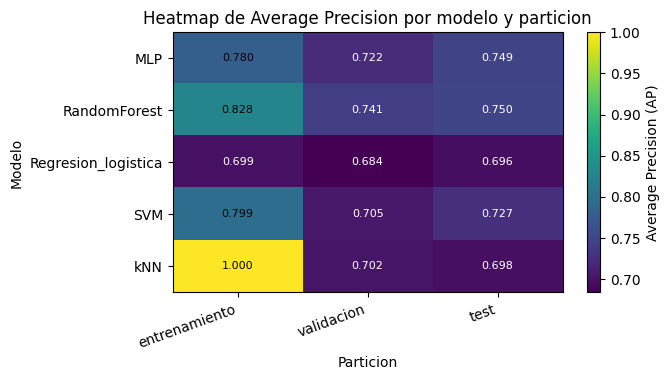

In [8]:
if metricas is not None and {"modelo", "particion", "AP"}.issubset(metricas.columns):
    import matplotlib.pyplot as plt
    import numpy as np

    pivote = metricas.pivot_table(
        index="modelo", columns="particion", values="AP", aggfunc="mean"
    )
    orden = [p for p in ("entrenamiento", "validacion", "test") if p in pivote.columns]
    if orden:
        pivote = pivote[orden]
    datos = pivote.to_numpy(dtype=float)
    fig, eje = plt.subplots(figsize=(6.8, 3.9))
    imagen = eje.imshow(datos, cmap="viridis", aspect="auto")
    eje.set_xticks(range(len(pivote.columns)))
    eje.set_xticklabels([str(c) for c in pivote.columns], rotation=20, ha="right")
    eje.set_yticks(range(len(pivote.index)))
    eje.set_yticklabels([str(i) for i in pivote.index])
    eje.set_xlabel("Particion")
    eje.set_ylabel("Modelo")
    eje.set_title("Heatmap de Average Precision por modelo y particion")
    limite = np.nanmean(datos) if np.isfinite(datos).any() else 0.0
    for i in range(datos.shape[0]):
        for j in range(datos.shape[1]):
            valor = datos[i, j]
            texto = f"{valor:.3f}" if np.isfinite(valor) else "NA"
            eje.text(
                j,
                i,
                texto,
                ha="center",
                va="center",
                color="white" if valor < limite else "black",
                fontsize=8,
            )
    fig.colorbar(imagen, ax=eje, label="Average Precision (AP)")
    fig.tight_layout()
    plt.show()
else:
    print("AVISO: no hay tabla de metricas para construir el heatmap.")

## 6. Reducción de dimensión

La reducción se ajusta dentro del `Pipeline`, solo con entrenamiento. El barrido PCA y UMAP se
evalúa por validación cruzada y validación; la prueba se consulta después de fijar las variantes.
Las tablas siguientes leen `reduccion_cv.csv`, `reduccion_validacion.csv`,
`reduccion_test.csv`, `pca_varianza.csv`, `pca_barrido.csv`, `umap_barrido.csv`,
`reduccion_comparacion.csv` y `reduccion_protocolo.json`. Los intervalos bootstrap por variante
viajan como columnas de `reduccion_test.csv`.

In [9]:
reduccion_cv = leer_csv(("reduccion", "reduccion_cv.csv"), "Reduccion: validacion cruzada")
reduccion_validacion = leer_csv(
    ("reduccion", "reduccion_validacion.csv"), "Reduccion: resultados en validacion"
)
reduccion_test = leer_csv(
    ("reduccion", "reduccion_test.csv"), "Reduccion: resultados en prueba"
)
if reduccion_test is not None:
    columnas_ic = [
        c
        for c in [
            "modelo",
            "metodo",
            "componentes",
            "AP",
            "media_bootstrap_AP",
            "ic_AP_inferior",
            "ic_AP_superior",
            "ROC_AUC",
            "media_bootstrap_ROC_AUC",
            "ic_ROC_AUC_inferior",
            "ic_ROC_AUC_superior",
        ]
        if c in reduccion_test.columns
    ]
    if len(columnas_ic) > 2:
        display(Markdown("**Prueba por variante con intervalos bootstrap por columna**"))
        display(reduccion_test[columnas_ic].round(4))
pca_varianza = leer_csv(
    ("reduccion", "pca_varianza.csv"), "PCA: primeras filas de varianza acumulada", filas=8
)
pca_varianza_familias = leer_csv(
    ("reduccion", "pca_varianza_familias.csv"),
    "PCA: varianza acumulada por familia",
    filas=8,
)
if pca_varianza is not None and {
    "modelo",
    "componente",
    "varianza_acumulada",
}.issubset(pca_varianza.columns):
    n95 = (
        pca_varianza[pca_varianza["varianza_acumulada"] >= 0.95]
        .sort_values(["modelo", "componente"])
        .groupby("modelo", as_index=False)
        .head(1)
    )
    display(
        Markdown(
            "**Primer componente que alcanza el 95 % de varianza acumulada (por modelo)**"
        )
    )
    display(n95[["modelo", "componente", "varianza_acumulada"]].round(5))

pca_barrido = leer_csv(
    ("reduccion", "pca_barrido.csv"), "PCA: barrido de componentes"
)
umap_barrido = leer_csv(
    ("reduccion", "umap_barrido.csv"), "UMAP: barrido de dimensiones y vecinos"
)
reduccion_comparaciones = leer_csv(
    ("reduccion", "reduccion_comparacion.csv"),
    "Reduccion: diferencias pareadas contra la base en prueba",
)
protocolo_reduccion = leer_json(
    ("reduccion", "reduccion_protocolo.json"), "Protocolo de reduccion"
)
if protocolo_reduccion:
    seleccion = protocolo_reduccion.get("seleccion")
    if seleccion:
        display(Markdown("**Variantes seleccionadas por validacion**"))
        display(pd.DataFrame(seleccion).round(4))
    claves = ["n_folds", "n_boot", "regla_simplicidad", "limitacion", "prueba"]
    resumen_protocolo = {k: protocolo_reduccion[k] for k in claves if k in protocolo_reduccion}
    if resumen_protocolo:
        mostrar_json(resumen_protocolo, "Resumen del protocolo de reduccion")

**Reduccion: validacion cruzada** (`resultados/reduccion/reduccion_cv.csv`; 46 filas x 9 columnas)

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,AP_CV,std_CV,AP_folds,finalista
0,RandomForest,PCA,5.00,NaN,5,0.702170,0.025421,"[0.671328901850622, 0.6849038375849495, 0.6991296257433192, 0.7095142723667371, 0.7459737810279176]",True
1,RandomForest,PCA,10.00,NaN,10,0.719798,0.031735,"[0.6661472859833788, 0.7058433925204257, 0.7310246894785951, 0.7368788128225421, 0.7590980443306466]",True
2,RandomForest,PCA,15.00,NaN,15,0.728921,0.033953,"[0.669243078765772, 0.7167954667796406, 0.739957424461386, 0.7526893425791941, 0.7659186732163904]",True
3,RandomForest,PCA,20.00,NaN,20,0.728808,0.033740,"[0.6679989247524891, 0.718799678603015, 0.7424289499085206, 0.75136830881523, 0.7634431103626591]",True
4,RandomForest,PCA,28.00,NaN,28,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",True
5,RandomForest,PCA,35.00,NaN,35,0.726616,0.033392,"[0.6674201741549863, 0.7152102749459163, 0.7372239362457101, 0.7528290384257272, 0.7603967648872407]",True
6,RandomForest,PCA,45.00,NaN,45,0.724961,0.031144,"[0.6727379683953515, 0.7075683634014925, 0.7380035338316633, 0.7482660069572488, 0.7582286816432887]",True
7,RandomForest,PCA,0.95,NaN,28,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",True
8,RandomForest,UMAP,2.00,15.0,2,0.678690,0.027392,"[0.6399247486299001, 0.666414991558648, 0.6782954473834483, 0.6847192949003411, 0.7240964509787594]",True
9,RandomForest,UMAP,2.00,30.0,2,0.678839,0.031355,"[0.6289122824569696, 0.6712869065094977, 0.695435972169605, 0.6742328974579073, 0.7243271513208707]",True


**Reduccion: resultados en validacion** (`resultados/reduccion/reduccion_validacion.csv`; 50 filas x 22 columnas)

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,AP_CV,std_CV,AP_folds,varianza_acumulada,seleccionado,motivo_seleccion,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,AP_max_validacion,desviacion_std_CV,umbral_simplicidad,diferencia_con_max
0,RandomForest,Base,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,referencia_sin_reduccion,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354,NaN,NaN,NaN,NaN
1,RandomForest,PCA,5.00,NaN,5.0,0.702170,0.025421,"[0.671328901850622, 0.6849038375849495, 0.6991296257433192, 0.7095142723667371, 0.7459737810279176]",0.656386,True,simplicidad,0.693642,0.906501,0.687697,0.572178,0.624642,0.762060,0.892667,0.718395,0.031144,0.687251,0.024753
2,RandomForest,PCA,10.00,NaN,10.0,0.719798,0.031735,"[0.6661472859833788, 0.7058433925204257, 0.7310246894785951, 0.7368788128225421, 0.7590980443306466]",0.803802,False,NaN,0.707384,0.905127,0.693811,0.559055,0.619186,0.756712,0.892667,NaN,NaN,NaN,NaN
3,RandomForest,PCA,15.00,NaN,15.0,0.728921,0.033953,"[0.669243078765772, 0.7167954667796406, 0.739957424461386, 0.7526893425791941, 0.7659186732163904]",0.868771,False,NaN,0.715540,0.914253,0.693009,0.598425,0.642254,0.774698,0.895944,NaN,NaN,NaN,NaN
4,RandomForest,PCA,20.00,NaN,20.0,0.728808,0.033740,"[0.6679989247524891, 0.718799678603015, 0.7424289499085206, 0.75136830881523, 0.7634431103626591]",0.911908,False,NaN,0.714437,0.913651,0.700617,0.595801,0.643972,0.774357,0.897173,NaN,NaN,NaN,NaN
5,RandomForest,PCA,28.00,NaN,28.0,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",0.953367,False,NaN,0.716483,0.915381,0.699387,0.598425,0.644979,0.775426,0.897173,NaN,NaN,NaN,NaN
6,RandomForest,PCA,35.00,NaN,35.0,0.726616,0.033392,"[0.6674201741549863, 0.7152102749459163, 0.7372239362457101, 0.7528290384257272, 0.7603967648872407]",0.975638,False,NaN,0.716433,0.915507,0.703704,0.598425,0.646809,0.775912,0.897993,NaN,NaN,NaN,NaN
7,RandomForest,PCA,45.00,NaN,45.0,0.724961,0.031144,"[0.6727379683953515, 0.7075683634014925, 0.7380035338316633, 0.7482660069572488, 0.7582286816432887]",0.994005,False,NaN,0.718395,0.917059,0.700906,0.608924,0.651685,0.780433,0.898402,NaN,NaN,NaN,NaN
8,RandomForest,PCA,0.95,NaN,28.0,0.726476,0.032068,"[0.6695868177556571, 0.7156596263869749, 0.7376265744263892, 0.7490516665367857, 0.7604543535107027]",0.953367,False,NaN,0.716483,0.915381,0.699387,0.598425,0.644979,0.775426,0.897173,NaN,NaN,NaN,NaN
9,RandomForest,UMAP,2.00,15.0,2.0,0.678690,0.027392,"[0.6399247486299001, 0.666414991558648, 0.6782954473834483, 0.6847192949003411, 0.7240964509787594]",NaN,False,NaN,0.653088,0.891500,0.658273,0.480315,0.555387,0.717099,0.879967,NaN,NaN,NaN,NaN


**Reduccion: resultados en prueba** (`resultados/reduccion/reduccion_test.csv`; 8 filas x 38 columnas)

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,AP_CV,std_CV,AP_validacion,varianza_acumulada,n_boot,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,media_bootstrap_AP,ic_AP_inferior,ic_AP_superior,media_bootstrap_ROC_AUC,ic_ROC_AUC_inferior,ic_ROC_AUC_superior,media_bootstrap_precision,ic_precision_inferior,ic_precision_superior,media_bootstrap_recall,ic_recall_inferior,ic_recall_superior,media_bootstrap_F1,ic_F1_inferior,ic_F1_superior,media_bootstrap_balanced_accuracy,ic_balanced_accuracy_inferior,ic_balanced_accuracy_superior,media_bootstrap_accuracy,ic_accuracy_inferior,ic_accuracy_superior
0,RandomForest,PCA,5.0,NaN,5.0,0.702170,0.025421,0.693642,0.656386,2000,0.689727,0.904133,0.688136,0.531414,0.599705,0.743366,0.888980,0.691318,0.647744,0.730870,0.904461,0.887233,0.920939,0.689603,0.641692,0.734988,0.531088,0.481675,0.581152,0.599727,0.557426,0.642654,0.743331,0.718294,0.768966,0.889145,0.878329,0.899631
1,RandomForest,UMAP,5.0,30.0,5.0,0.693724,0.027708,0.675420,NaN,2000,0.666305,0.886007,0.659864,0.507853,0.573964,0.729643,0.882016,0.667383,0.623799,0.709537,0.886260,0.866759,0.904220,0.660513,0.612786,0.708192,0.507791,0.458115,0.560209,0.573860,0.529050,0.617991,0.729652,0.704233,0.756123,0.882073,0.870545,0.893077
2,RandomForest,UMAP2D,2.0,15.0,2.0,NaN,NaN,0.653088,NaN,2000,0.659540,0.888349,0.656934,0.471204,0.548780,0.712775,0.878738,0.660829,0.618995,0.701904,0.888661,0.869618,0.905917,0.657787,0.607140,0.708819,0.470652,0.418848,0.520942,0.548383,0.502339,0.593796,0.712580,0.686445,0.737857,0.878787,0.868087,0.889799
3,RandomForest,Base,NaN,NaN,NaN,NaN,NaN,0.741404,NaN,2000,0.749559,0.930164,0.744262,0.594241,0.660844,0.778179,0.904547,0.750543,0.713407,0.786883,0.930434,0.917772,0.942950,0.744684,0.700641,0.788599,0.594101,0.544503,0.641361,0.660620,0.621097,0.698370,0.778117,0.753401,0.801647,0.904538,0.894715,0.914379
4,MLP,PCA,10.0,NaN,10.0,0.728751,0.033598,0.711292,0.803802,2000,0.728415,0.915539,0.684058,0.617801,0.649243,0.782431,0.895535,0.729269,0.687724,0.767913,0.915801,0.900193,0.930121,0.685478,0.642843,0.727811,0.617641,0.568063,0.667539,0.649526,0.610949,0.687671,0.782487,0.758328,0.806579,0.895738,0.884474,0.906606
5,MLP,UMAP,2.0,50.0,2.0,0.662350,0.023012,0.637724,NaN,2000,0.634906,0.860612,0.682008,0.426702,0.524960,0.694895,0.879148,0.636598,0.588417,0.681860,0.860949,0.837458,0.880985,0.682839,0.629015,0.736842,0.425785,0.376963,0.476440,0.524155,0.476647,0.570064,0.694519,0.669444,0.719672,0.879142,0.868896,0.889390
6,MLP,UMAP2D,2.0,15.0,2.0,NaN,NaN,0.604236,NaN,2000,0.581463,0.852172,0.640411,0.489529,0.554896,0.719267,0.877100,0.585484,0.536582,0.637002,0.852647,0.829106,0.874631,0.641592,0.594933,0.690765,0.489280,0.439725,0.539267,0.554863,0.508977,0.597668,0.719251,0.693709,0.744627,0.877244,0.866448,0.888161
7,MLP,Base,NaN,NaN,NaN,NaN,NaN,0.722479,NaN,2000,0.749373,0.928356,0.715655,0.586387,0.644604,0.771581,0.898812,0.750369,0.712699,0.787315,0.928557,0.914971,0.940975,0.716630,0.671510,0.761294,0.585965,0.539202,0.636126,0.644447,0.604046,0.683763,0.771448,0.747481,0.796169,0.898878,0.888161,0.909463


... (15 outputs left out)

**Variantes seleccionadas por validacion**

,modelo,metodo,dimensiones_solicitadas,componentes,vecinos,AP_CV,std_CV,AP_validacion,varianza_acumulada,motivo_seleccion,diferencia_con_max,umbral_simplicidad,desviacion_std_CV,AP_max_validacion
0,RandomForest,PCA,5,5,NaN,0.7022,0.0254,0.6936,0.6564,simplicidad,0.0248,0.6873,0.0311,0.7184
1,RandomForest,UMAP,5,5,30.0,0.6937,0.0277,0.6754,NaN,simplicidad,0.0205,0.6743,0.0216,0.6959
2,MLP,PCA,10,10,NaN,0.7288,0.0336,0.7113,0.8038,simplicidad,0.0230,0.6987,0.0357,0.7343
3,MLP,UMAP,2,2,50.0,0.6624,0.0230,0.6377,NaN,simplicidad,0.0154,0.6244,0.0287,0.6531


**Resumen del protocolo de reduccion**

```json
{
  "n_folds": 5,
  "n_boot": 2000,
  "regla_simplicidad": {
    "criterio": "se parte del mayor AP de validacion; una variante mas simple lo sustituye si su AP_validacion >= AP_max - std_CV del ganador",
    "desviacion": "std_CV poblacional entre folds del candidato con mayor AP de validacion; un valor no finito se trata como 0",
    "frontera": "la igualdad cuenta como dentro del umbral (diferencia <= std_CV); con std_CV=0 solo los empates exactos activan la simplicidad",
    "complejidad_umap": "menor n_components; a igualdad, mayor n_neighbors",
    "complejidad_pca": "menor numero de componentes ajustado; a igualdad, valor fijo antes que 0.95",
    "empates": "orden determinista por la clave de simplicidad y luego por el orden de la rejilla"
  },
  "limitacion": "la particion de prueba fue consultada historicamente; los IC son condicionales a las variantes fijadas",
  "prueba": "test se consulta solo despues de fijar todas las variantes; no participa en la seleccion"
}
```

## 7. Variables y eliminacion

El análisis descriptivo usa solo entrenamiento: correlación punto-biserial o V de Cramer, AUC
univariado e información mutua. La eliminacion compara las configuraciones de Random Forest y
MLP con todas las variables, sin las candidatas de menor AUC y sin las numéricas redundantes.
La prueba no participa en estas decisiones.

In [10]:
analisis_variables = leer_csv(
    ("variables", "analisis_variables.csv"), "Analisis univariado de variables"
)
redundancia = leer_csv(
    ("variables", "redundancia_numericas.csv"),
    "Pares de variables numericas con correlacion absoluta >= 0.8",
)
eliminacion_validacion = leer_csv(
    ("variables", "eliminacion_validacion.csv"),
    "Eliminacion de variables: resultados en validacion",
)
eliminacion_cv = leer_csv(
    ("variables", "eliminacion_cv.csv"), "Eliminacion de variables: validacion cruzada"
)
resumen_eliminacion = leer_json(
    ("variables", "eliminacion_resumen.json"), "Resumen de eliminacion de variables"
)
if resumen_eliminacion:
    claves = [
        "candidatas",
        "criterio_candidatas",
        "n_folds",
        "n_entrenamiento",
        "n_validacion",
        "prueba",
    ]
    mostrar_json(
        {k: resumen_eliminacion[k] for k in claves if k in resumen_eliminacion},
        "Protocolo de eliminacion",
    )

**Analisis univariado de variables** (`resultados/variables/analisis_variables.csv`; 17 filas x 10 columnas)

,variable,tipo,metrica,valor,p_valor,auc_univariado,direccion,informacion_mutua,ranking,recomendacion
0,PageValues,numérica,correlación punto-biserial,0.488849,0.000000e+00,0.866362,positiva,0.165087,1,mantener
1,ExitRates,numérica,correlación punto-biserial,-0.210426,4.434559e-74,0.710126,negativa,0.042920,2,mantener
2,ProductRelated_Duration,numérica,correlación punto-biserial,0.141842,3.197950e-34,0.668875,positiva,0.031664,3,mantener
3,ProductRelated,numérica,correlación punto-biserial,0.156095,3.626287e-41,0.658200,positiva,0.029647,4,mantener
4,Administrative,numérica,correlación punto-biserial,0.132891,3.292128e-30,0.625789,positiva,0.015745,5,mantener
5,TrafficType,categórica,V de Cramér,0.177351,NaN,0.625124,positiva,0.016062,6,mantener
6,Administrative_Duration,numérica,correlación punto-biserial,0.075871,7.985450e-11,0.620179,positiva,0.013561,7,mantener
7,Month,categórica,V de Cramér,0.171862,NaN,0.615963,positiva,0.014715,8,mantener
8,BounceRates,numérica,correlación punto-biserial,-0.147691,5.467656e-37,0.612409,negativa,0.026788,9,mantener
9,Informational,numérica,correlación punto-biserial,0.089650,1.519148e-14,0.557870,positiva,0.006738,10,revisar


**Pares de variables numericas con correlacion absoluta >= 0.8** (`resultados/variables/redundancia_numericas.csv`; 2 filas x 3 columnas)

,variable_1,variable_2,correlacion
0,ProductRelated,ProductRelated_Duration,0.842609
1,BounceRates,ExitRates,0.898962


**Eliminacion de variables: resultados en validacion** (`resultados/variables/eliminacion_validacion.csv`; 6 filas x 12 columnas)

,modelo,variante,excluidas,AP_CV,std_CV,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy
0,RandomForest,completo,NaN,0.757273,0.023408,0.741404,0.926500,0.702532,0.582677,0.637016,0.768523,0.896354
1,RandomForest,sin_5_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay,0.756462,0.023089,0.742213,0.926930,0.704762,0.582677,0.637931,0.768766,0.896764
2,RandomForest,sin_redundantes,ProductRelated_Duration;BounceRates,0.748463,0.026756,0.734773,0.927299,0.705329,0.590551,0.642857,0.772460,0.897583
3,MLP,completo,NaN,0.737548,0.034179,0.722479,0.924230,0.716088,0.595801,0.650430,0.776056,0.900041
4,MLP,sin_5_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay,0.735598,0.030475,0.725371,0.924994,0.711538,0.582677,0.640693,0.769494,0.897993
5,MLP,sin_redundantes,ProductRelated_Duration;BounceRates,0.735852,0.032524,0.725033,0.919244,0.724590,0.580052,0.644315,0.769638,0.900041


**Eliminacion de variables: validacion cruzada** (`resultados/variables/eliminacion_cv.csv`; 6 filas x 6 columnas)

,modelo,variante,excluidas,AP_CV,std_CV,AP_folds
0,RandomForest,completo,NaN,0.757273,0.023408,"[0.7175583526632671, 0.745449251473784, 0.7717370907554228, 0.7678669071913788, 0.7837527009915638]"
1,RandomForest,sin_5_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay,0.756462,0.023089,"[0.7175080877957474, 0.7434713007640485, 0.7697810724042177, 0.7704865324682506, 0.781063872456864]"
2,RandomForest,sin_redundantes,ProductRelated_Duration;BounceRates,0.748463,0.026756,"[0.7080889014003262, 0.7252638628877954, 0.7650218103565047, 0.7679949557378642, 0.7759474643065052]"
3,MLP,completo,NaN,0.737548,0.034179,"[0.6812683498038121, 0.7172874545388145, 0.7557240936350351, 0.777443767478738, 0.7560139969030542]"
4,MLP,sin_5_candidatas,Weekend;Region;Browser;VisitorType;SpecialDay,0.735598,0.030475,"[0.6847823011866412, 0.7172620164247206, 0.7493078639428642, 0.7631645609726911, 0.7634757199230734]"
5,MLP,sin_redundantes,ProductRelated_Duration;BounceRates,0.735852,0.032524,"[0.6799119381059874, 0.7198345114565242, 0.7495597948007591, 0.7680233182541689, 0.7619323633159214]"


**Resumen de eliminacion de variables** (`resultados/variables/eliminacion_resumen.json`)

**Protocolo de eliminacion**

```json
{
  "candidatas": [
    "Weekend",
    "Region",
    "Browser",
    "VisitorType",
    "SpecialDay"
  ],
  "criterio_candidatas": "cinco variables candidatas fijadas antes del experimento",
  "n_folds": 5,
  "n_entrenamiento": 7323,
  "n_validacion": 2441,
  "prueba": "no participa en el analisis ni en la eliminacion"
}
```

## 8. SpecialDay

La ablacion compara, por familia, el AP de validación con y sin `SpecialDay`. La comparación de
codificación contrasta la columna numérica con one-hot de seis niveles. La tabla por mes es
opcional y solo usa validación. Los resultados se leen de `specialday_ablacion.csv`,
`specialday_codificacion.csv` y `specialday_por_mes.csv`.

In [11]:
ablacion_specialday = leer_csv(
    "specialday_ablacion.csv", "SpecialDay: ablacion por familia"
)
codificacion_specialday = leer_csv(
    "specialday_codificacion.csv", "SpecialDay: comparacion de codificacion"
)
por_mes_specialday = leer_csv(
    "specialday_por_mes.csv", "SpecialDay: AP del ganador por mes de validacion"
)

**SpecialDay: ablacion por familia** (`resultados/specialday_ablacion.csv`; 5 filas x 5 columnas)

,modelo,AP_con_SpecialDay,AP_sin_SpecialDay,delta_AP_con_menos_sin,params
0,Regresion_logistica,0.684086,0.684458,-0.000372,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"
1,kNN,0.701831,0.706630,-0.004799,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
2,RandomForest,0.741404,0.741774,-0.000370,"{'clf__class_weight': None, 'clf__max_depth': 8, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 20, 'p..."
3,MLP,0.722479,0.718074,0.004405,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.03, 'pre__num__log__usa..."
4,SVM,0.705417,0.704042,0.001375,"{'clf__C': 30, 'clf__class_weight': None, 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__usar_l..."


**SpecialDay: comparacion de codificacion** (`resultados/specialday_codificacion.csv`; 5 filas x 13 columnas)

,modelo,AP_CV_numerico,std_CV_numerico,AP_CV_onehot,std_CV_onehot,delta_AP_CV_onehot_menos_numerico,AP_validacion_numerico,AP_validacion_onehot,delta_AP_validacion_onehot_menos_numerico,n_columnas_numerico,n_columnas_onehot,folds_numerico,folds_onehot
0,Regresion_logistica,0.689679,0.031968,0.690747,0.032692,0.001068,0.684086,0.683523,-0.000564,73,78,"[0.6288985682674647, 0.712407614417046, 0.6922771935312317, 0.6959213147616863, 0.7188901809450964]","[0.6281863220926237, 0.7137966115830792, 0.6942044597074853, 0.6978926488447172, 0.7196569974407684]"
1,kNN,0.717198,0.023194,0.721572,0.025380,0.004374,0.701831,0.706456,0.004625,73,78,"[0.6864034333248556, 0.706059637835591, 0.7160910369435487, 0.7201429050748082, 0.7572926171212431]","[0.6845618592974622, 0.708283186475248, 0.7209779025130185, 0.7332550066553486, 0.7607834062665132]"
2,RandomForest,0.757273,0.023408,0.755575,0.024264,-0.001698,0.741404,0.741774,0.000370,73,78,"[0.7175583526632671, 0.745449251473784, 0.7717370907554228, 0.7678669071913788, 0.7837527009915638]","[0.7148890159904973, 0.7413412328031802, 0.7734222994829939, 0.7677812205358824, 0.7804418493078288]"
3,MLP,0.737548,0.034179,0.736536,0.037293,-0.001012,0.722479,0.732152,0.009673,73,78,"[0.6812683498038121, 0.7172874545388145, 0.7557240936350351, 0.777443767478738, 0.7560139969030542]","[0.6708131670760575, 0.7199232444583861, 0.757252495399496, 0.771271803007029, 0.7634168135048687]"
4,SVM,0.725999,0.035145,0.728743,0.035359,0.002745,0.705417,0.698814,-0.006603,73,78,"[0.6702588831723362, 0.7040586796569613, 0.7385689319175782, 0.7461005887993346, 0.77100564312203]","[0.6697263199193544, 0.7093310654244187, 0.7447307451015286, 0.7503104842290673, 0.7696169462637175]"


**SpecialDay: AP del ganador por mes de validacion** (`resultados/specialday_por_mes.csv`; 10 filas x 5 columnas)

,modelo,mes,n,positivos,AP_validacion
0,RandomForest,Feb,37,0,NaN
1,RandomForest,Mar,359,38,0.785284
2,RandomForest,May,663,74,0.876918
3,RandomForest,June,58,7,0.690011
4,RandomForest,Jul,96,15,0.598316
5,RandomForest,Aug,76,8,0.567959
6,RandomForest,Sep,87,17,0.838979
7,RandomForest,Oct,98,15,0.589077
8,RandomForest,Nov,633,166,0.682606
9,RandomForest,Dec,334,41,0.766951


## 9. Sensibilidad a PageValues

La sensibilidad repite la selección de las cinco familias sin `PageValues`, con la misma malla y
la misma regla top-3. La comparación principal y las configuraciones sin esa variable se leen de
`comparacion_pagevalues.csv` y `mejores_sin_pagevalues.csv`.

In [12]:
comparacion_pagevalues = leer_csv(
    "comparacion_pagevalues.csv", "Sensibilidad: comparacion con y sin PageValues"
)
mejores_sin_pagevalues = leer_csv(
    "mejores_sin_pagevalues.csv", "Mejores configuraciones sin PageValues"
)

**Sensibilidad: comparacion con y sin PageValues** (`resultados/comparacion_pagevalues.csv`; 5 filas x 7 columnas)

,modelo,AP_con,ROC_AUC_con,AP_sin,ROC_AUC_sin,params,delta_AP
0,RandomForest,0.741404,0.926500,0.384824,0.784684,"{'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_l...",0.356580
1,MLP,0.722479,0.924230,0.353228,0.765268,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.01, 'pre__num__log__usa...",0.369250
2,SVM,0.705417,0.900071,0.340259,0.768538,"{'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__u...",0.365158
3,kNN,0.701831,0.912418,0.347742,0.761518,"{'clf__n_neighbors': 101, 'clf__p': 1, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}",0.354089
4,Regresion_logistica,0.684086,0.912316,0.334490,0.761583,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}",0.349597


**Mejores configuraciones sin PageValues** (`resultados/mejores_sin_pagevalues.csv`; 5 filas x 12 columnas)

,AP,ROC_AUC,precision,recall,F1,balanced_accuracy,accuracy,modelo,rango_cv,AP_CV,std_CV,params
0,0.384824,0.784684,0.384289,0.475066,0.424883,0.667144,0.799263,RandomForest,1,0.388310,0.036455,"{'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_l..."
1,0.353228,0.765268,0.470588,0.041995,0.077108,0.516628,0.843097,MLP,3,0.358650,0.032075,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (64,), 'clf__learning_rate_init': 0.01, 'pre__num__log__usa..."
2,0.347742,0.761518,0.000000,0.000000,0.000000,0.499757,0.843507,kNN,2,0.336228,0.019433,"{'clf__n_neighbors': 101, 'clf__p': 1, 'clf__weights': 'distance', 'pre__num__log__usar_log': True}"
3,0.340259,0.768538,0.259041,0.808399,0.392357,0.690365,0.609177,SVM,2,0.342799,0.020540,"{'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__gamma': 0.01, 'clf__kernel': 'rbf', 'pre__num__log__u..."
4,0.334490,0.761583,0.285714,0.015748,0.029851,0.504233,0.840229,Regresion_logistica,1,0.349300,0.022576,"{'clf__C': 0.1, 'clf__class_weight': None, 'pre__num__log__usar_log': True}"


## 10. Comparaciones pareadas

Las comparaciones de evaluación usan bootstrap pareado sobre las puntuaciones de prueba para AP
y ROC-AUC. Las de reducción comparan las variantes fijadas. Se muestran las tablas completas y,
por separado, las filas cuyo intervalo del 95 % excluye cero; esa separacion es una lectura
descriptiva y no convierte los intervalos en una prueba independiente.

In [13]:
comparaciones_evaluacion = leer_csv_variantes(
    [
        ("evaluacion_familias", "comparaciones_test.csv"),
        ("evaluacion_familias", "comparaciones_ap_test.csv"),
    ],
    "Comparaciones pareadas de evaluacion en prueba",
)

if comparaciones_evaluacion is not None and {
    "ic_inferior",
    "ic_superior",
}.issubset(comparaciones_evaluacion.columns):
    significativas = comparaciones_evaluacion[
        (comparaciones_evaluacion["ic_inferior"] > 0)
        | (comparaciones_evaluacion["ic_superior"] < 0)
    ].copy()
    display(
        Markdown(
            f"**Intervalos que excluyen cero: {len(significativas)} de "
            f"{len(comparaciones_evaluacion)} filas**"
        )
    )
    display(significativas.round(4))

if reduccion_comparaciones is not None and {
    "ic_inferior",
    "ic_superior",
}.issubset(reduccion_comparaciones.columns):
    significativas_red = reduccion_comparaciones[
        (reduccion_comparaciones["ic_inferior"] > 0)
        | (reduccion_comparaciones["ic_superior"] < 0)
    ].copy()
    display(
        Markdown(
            f"**Reduccion: intervalos que excluyen cero: {len(significativas_red)} de "
            f"{len(reduccion_comparaciones)} filas**"
        )
    )
    display(significativas_red.round(4))

**Comparaciones pareadas de evaluacion en prueba** (`resultados/evaluacion_familias/comparaciones_test.csv`; 20 filas x 8 columnas)

,modelo_a,modelo_b,metrica,diferencia_puntual,media_bootstrap,ic_inferior,ic_superior,n_boot
0,RandomForest,MLP,AP,0.000186,0.000174,-0.019023,0.019046,2000
1,RandomForest,MLP,ROC_AUC,0.001808,0.001878,-0.003550,0.007505,2000
2,RandomForest,SVM,AP,0.022368,0.022310,0.000105,0.044985,2000
3,RandomForest,SVM,ROC_AUC,0.026753,0.026965,0.014360,0.040621,2000
4,RandomForest,kNN,AP,0.052004,0.051549,0.030420,0.073651,2000
5,RandomForest,kNN,ROC_AUC,0.022662,0.022563,0.015115,0.030681,2000
6,RandomForest,Regresion_logistica,AP,0.053926,0.053073,0.024366,0.081249,2000
7,RandomForest,Regresion_logistica,ROC_AUC,0.019187,0.019103,0.010694,0.028877,2000
8,MLP,SVM,AP,0.022182,0.022137,0.006788,0.037929,2000
9,MLP,SVM,ROC_AUC,0.024945,0.025087,0.013010,0.038172,2000


**Intervalos que excluyen cero: 14 de 20 filas**

,modelo_a,modelo_b,metrica,diferencia_puntual,media_bootstrap,ic_inferior,ic_superior,n_boot
2,RandomForest,SVM,AP,0.0224,0.0223,0.0001,0.0450,2000
3,RandomForest,SVM,ROC_AUC,0.0268,0.0270,0.0144,0.0406,2000
4,RandomForest,kNN,AP,0.0520,0.0515,0.0304,0.0737,2000
5,RandomForest,kNN,ROC_AUC,0.0227,0.0226,0.0151,0.0307,2000
6,RandomForest,Regresion_logistica,AP,0.0539,0.0531,0.0244,0.0812,2000
7,RandomForest,Regresion_logistica,ROC_AUC,0.0192,0.0191,0.0107,0.0289,2000
8,MLP,SVM,AP,0.0222,0.0221,0.0068,0.0379,2000
9,MLP,SVM,ROC_AUC,0.0249,0.0251,0.0130,0.0382,2000
10,MLP,kNN,AP,0.0518,0.0514,0.0293,0.0735,2000
11,MLP,kNN,ROC_AUC,0.0209,0.0207,0.0130,0.0295,2000


**Reduccion: intervalos que excluyen cero: 12 de 12 filas**

,modelo,metodo,dimensiones_solicitadas,vecinos,componentes,metrica,valor,valor_base,diferencia_puntual,media_bootstrap,ic_inferior,ic_superior,n_boot
0,RandomForest,PCA,5,NaN,5,AP,0.6897,0.7496,-0.0598,-0.0592,-0.0823,-0.0373,2000
1,RandomForest,PCA,5,NaN,5,ROC_AUC,0.9041,0.9302,-0.0260,-0.0260,-0.0348,-0.0179,2000
2,RandomForest,UMAP,5,30.0,5,AP,0.6663,0.7496,-0.0833,-0.0832,-0.1113,-0.0559,2000
3,RandomForest,UMAP,5,30.0,5,ROC_AUC,0.8860,0.9302,-0.0442,-0.0442,-0.0569,-0.0322,2000
4,RandomForest,UMAP2D,2,15.0,2,AP,0.6595,0.7496,-0.0900,-0.0897,-0.1181,-0.0617,2000
5,RandomForest,UMAP2D,2,15.0,2,ROC_AUC,0.8883,0.9302,-0.0418,-0.0418,-0.0550,-0.0293,2000
6,MLP,PCA,10,NaN,10,AP,0.7284,0.7494,-0.0210,-0.0211,-0.0378,-0.0048,2000
7,MLP,PCA,10,NaN,10,ROC_AUC,0.9155,0.9284,-0.0128,-0.0128,-0.0204,-0.0056,2000
8,MLP,UMAP,2,50.0,2,AP,0.6349,0.7494,-0.1145,-0.1138,-0.1466,-0.0808,2000
9,MLP,UMAP,2,50.0,2,ROC_AUC,0.8606,0.9284,-0.0677,-0.0676,-0.0849,-0.0522,2000


## 11. Figuras generadas

Las seis figuras del informe se buscan por sus nombres reales en `resultados/figuras` y en
`informe_entregable_II_latex/figuras`. Las figuras del notebook se buscan por los nombres que
escribe el generador de figuras y también como `fig_nb_*.png`; si el generador cambia de
nomenclatura, el notebook las localiza por el patrón. Cada imagen se muestra y se acompaña de
un enlace relativo, sin imprimir rutas absolutas. Las figuras del notebook solo se toman de
`resultados/figuras`, de modo que no se muestren copias antiguas que quedaran en el directorio
del informe.

**Figura 1: clases y cobertura mensual** (`informe_entregable_II_latex/figuras/fig01_clases_cobertura.png`)

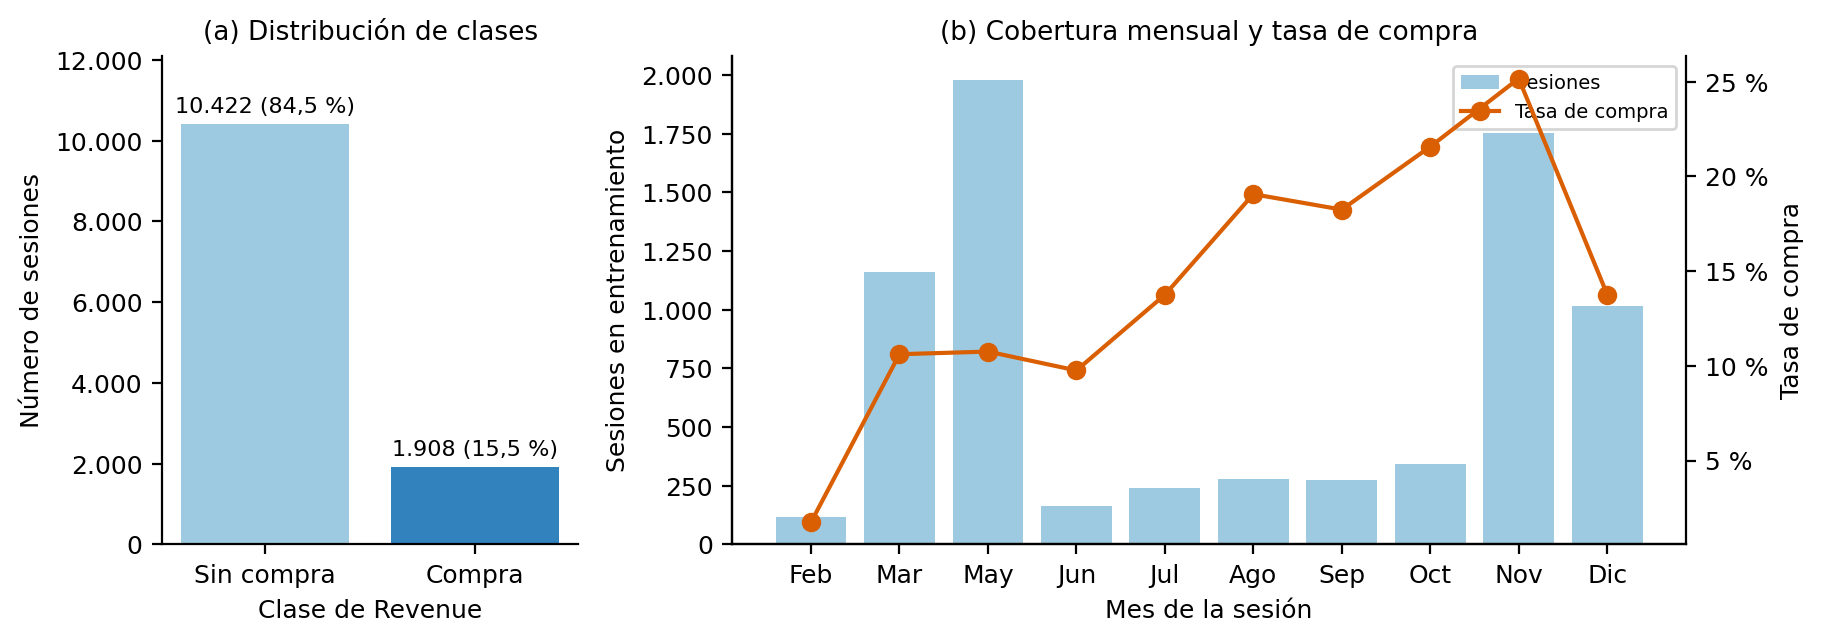

[Abrir figura: fig01_clases_cobertura.png](../informe_entregable_II_latex/figuras/fig01_clases_cobertura.png)

**Figura 2: efecto de los hiperparametros** (`informe_entregable_II_latex/figuras/fig02_hiperparametros.png`)

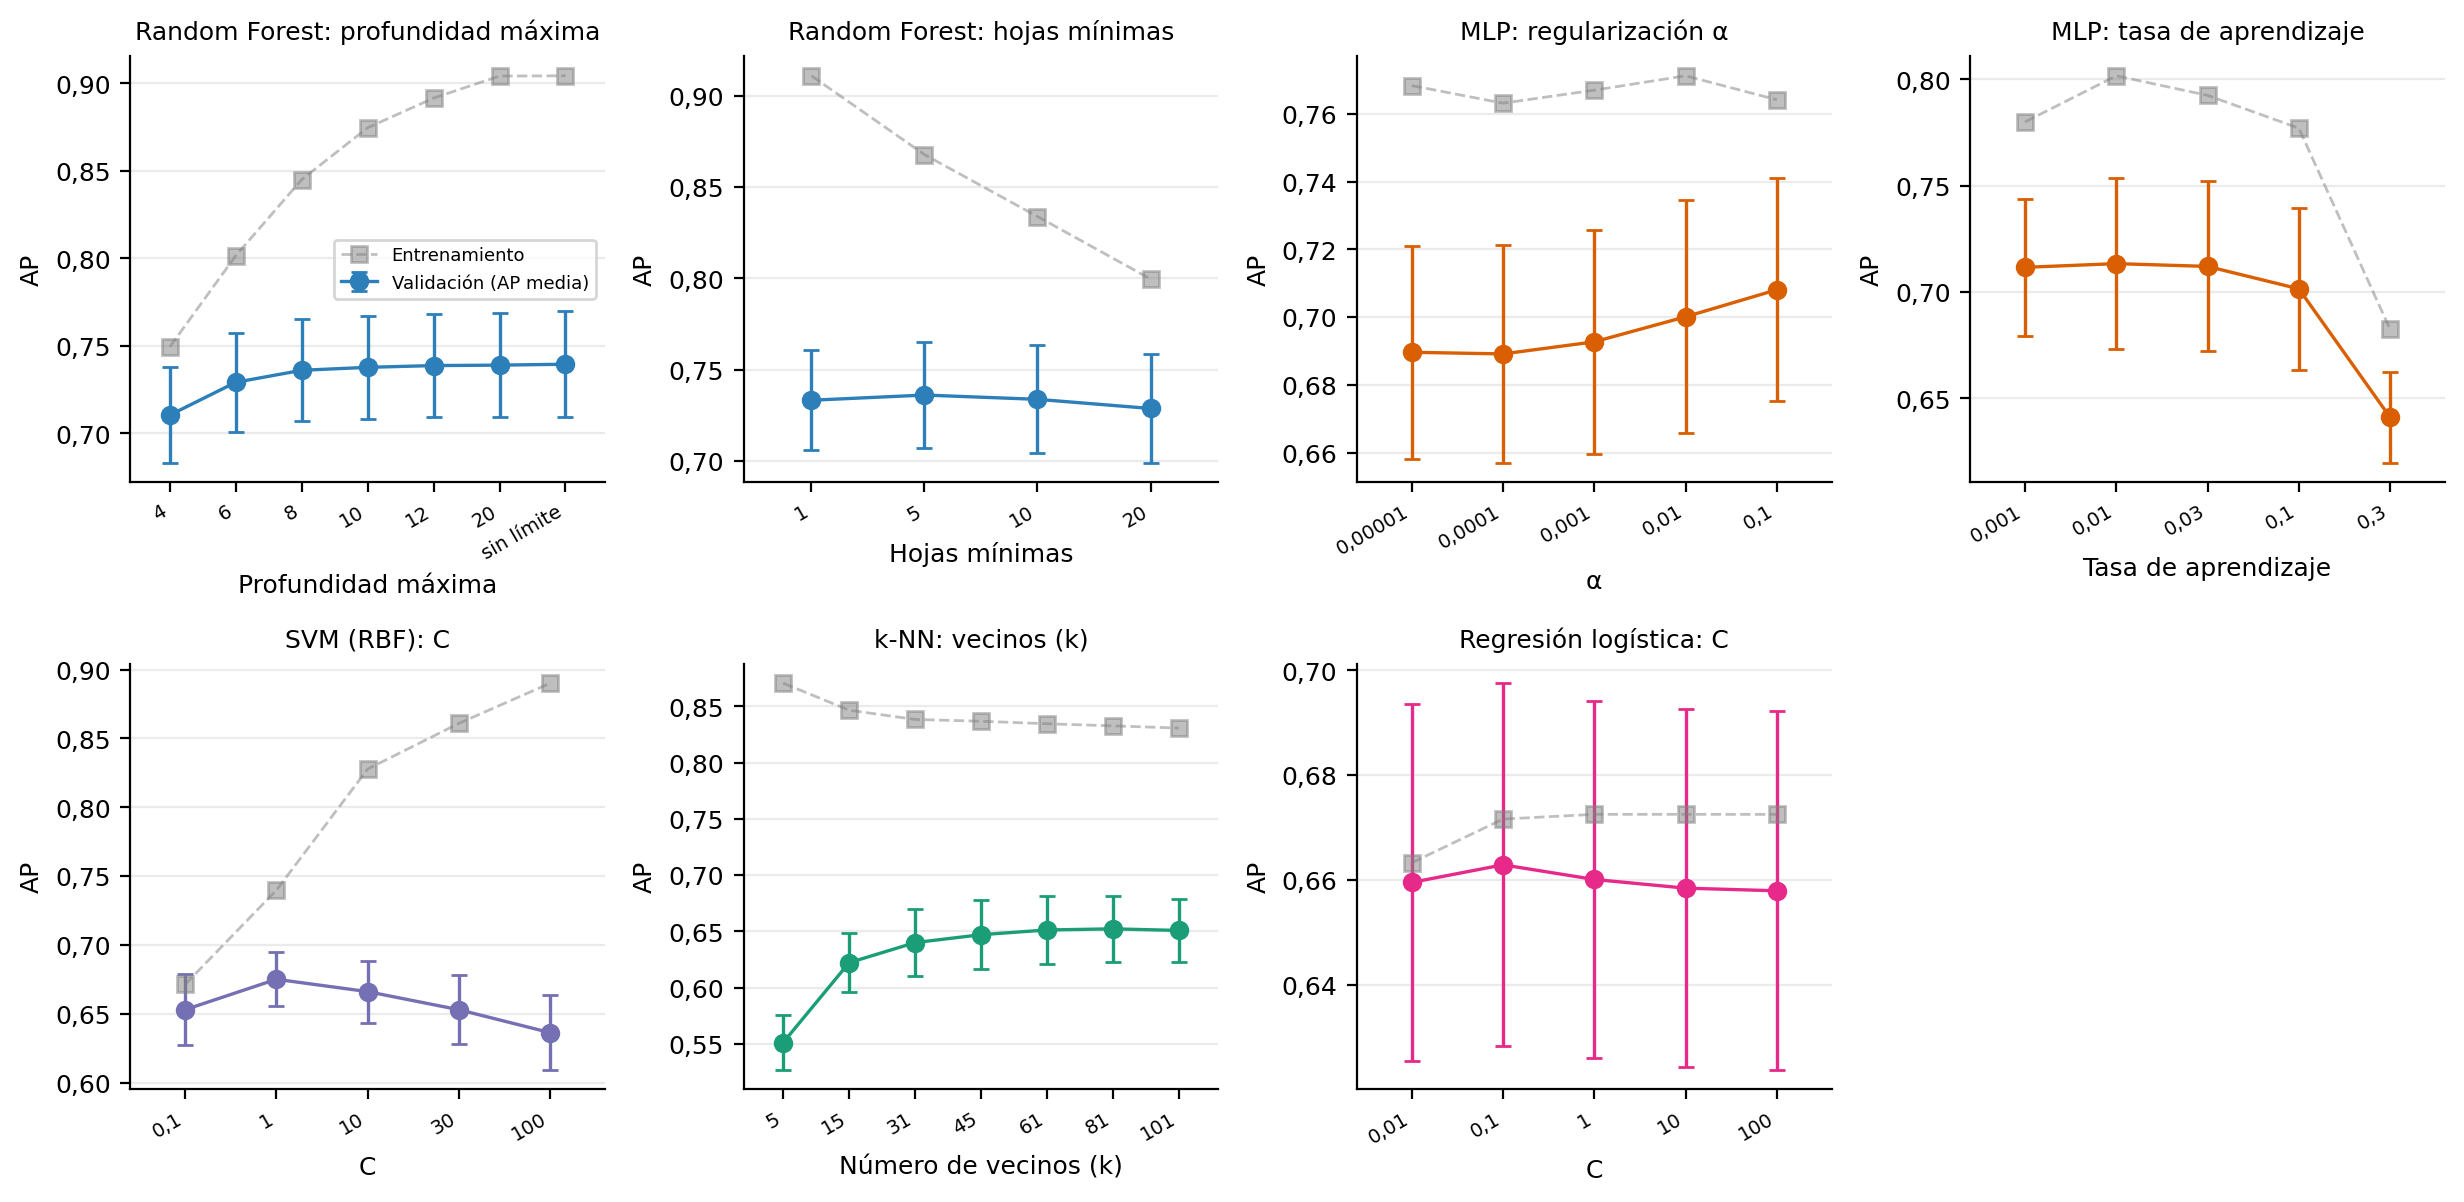

[Abrir figura: fig02_hiperparametros.png](../informe_entregable_II_latex/figuras/fig02_hiperparametros.png)

**Figura 3: curvas precision-recall y ROC en validacion** (`informe_entregable_II_latex/figuras/fig03_pr_roc_validacion.png`)

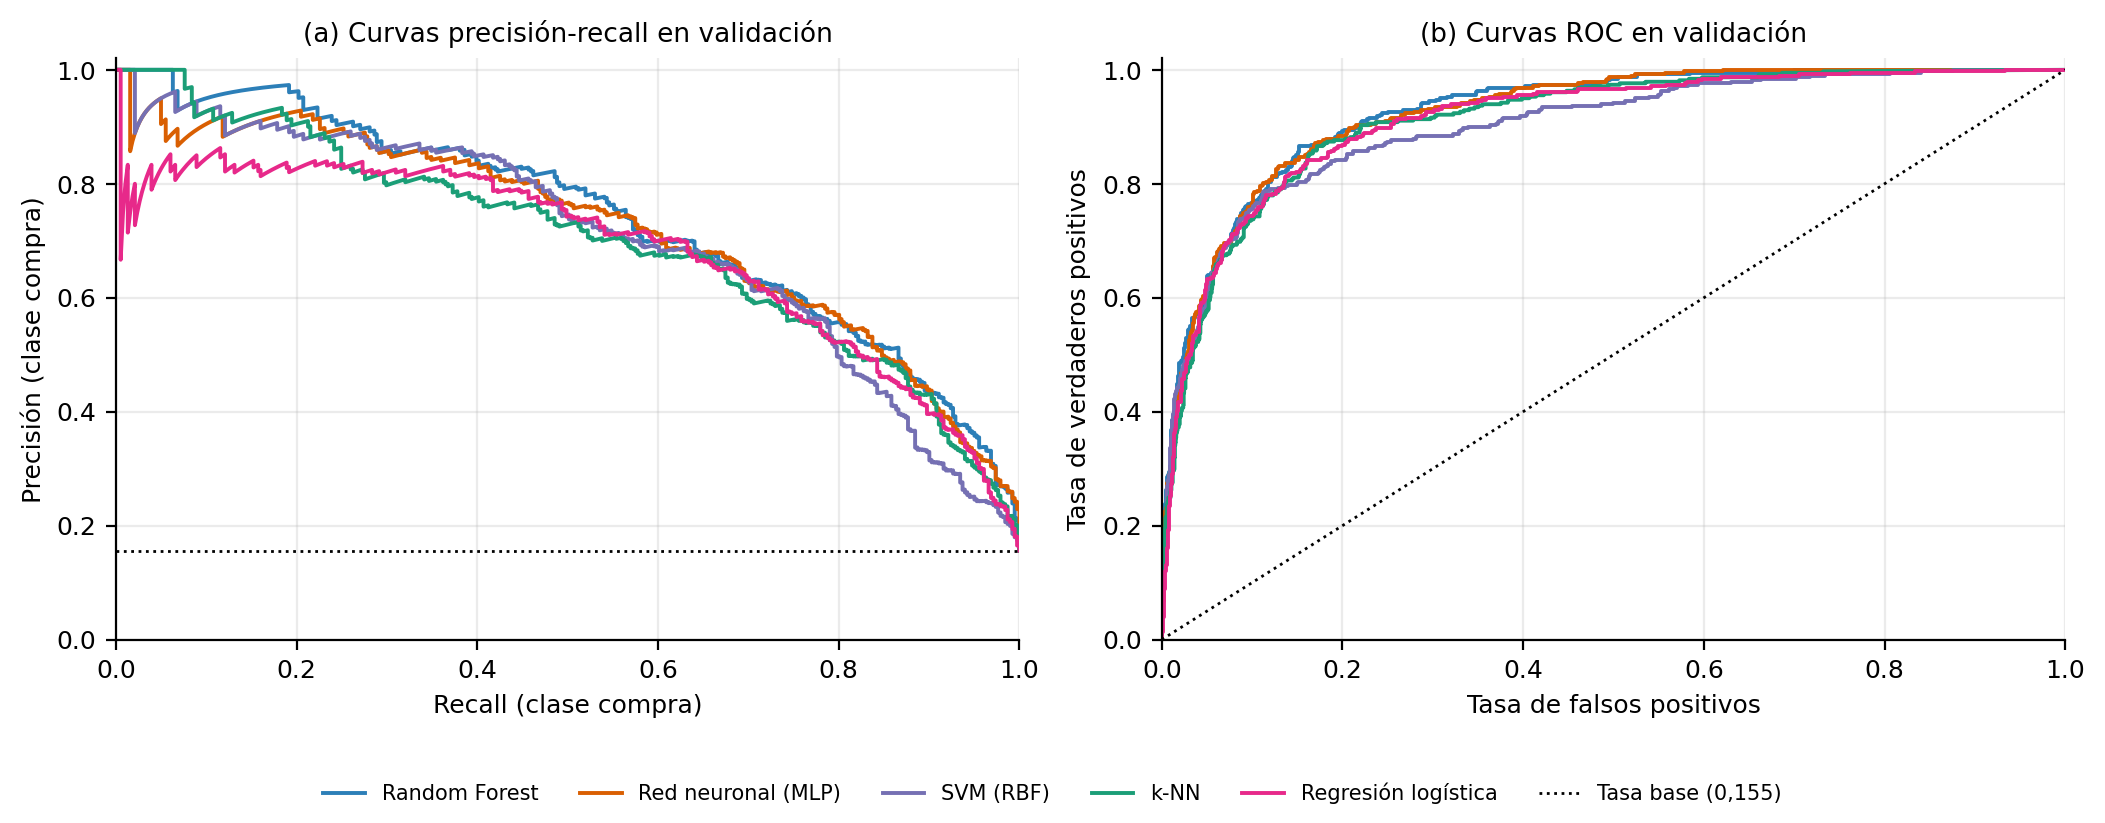

[Abrir figura: fig03_pr_roc_validacion.png](../informe_entregable_II_latex/figuras/fig03_pr_roc_validacion.png)

**Figura 4: variables con mayor AUC univariado** (`informe_entregable_II_latex/figuras/fig04_variables_auc.png`)

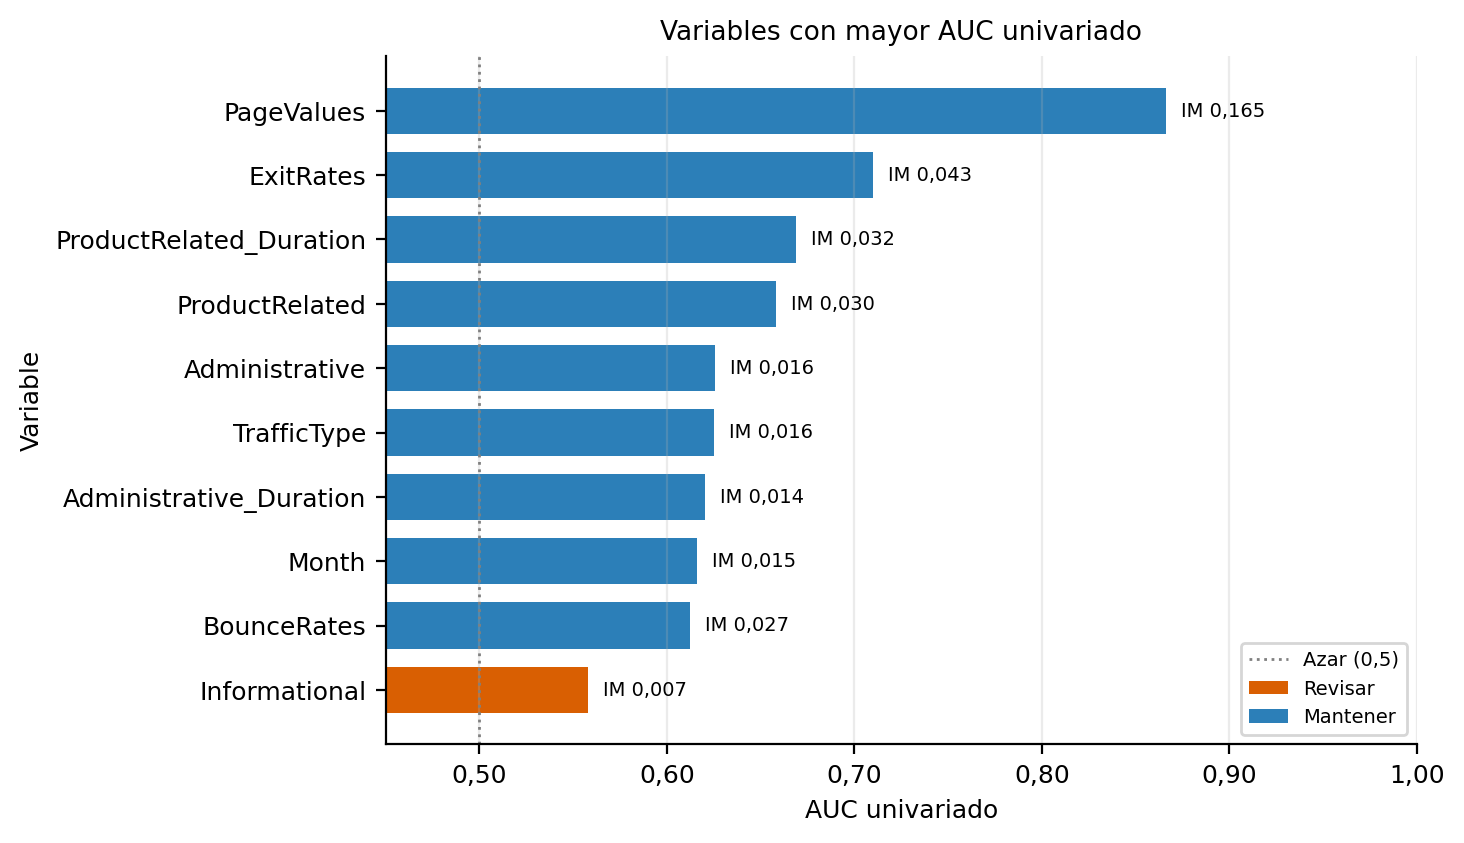

[Abrir figura: fig04_variables_auc.png](../informe_entregable_II_latex/figuras/fig04_variables_auc.png)

**Figura 5: PCA, UMAP y comparacion con la base** (`informe_entregable_II_latex/figuras/fig05_reduccion.png`)

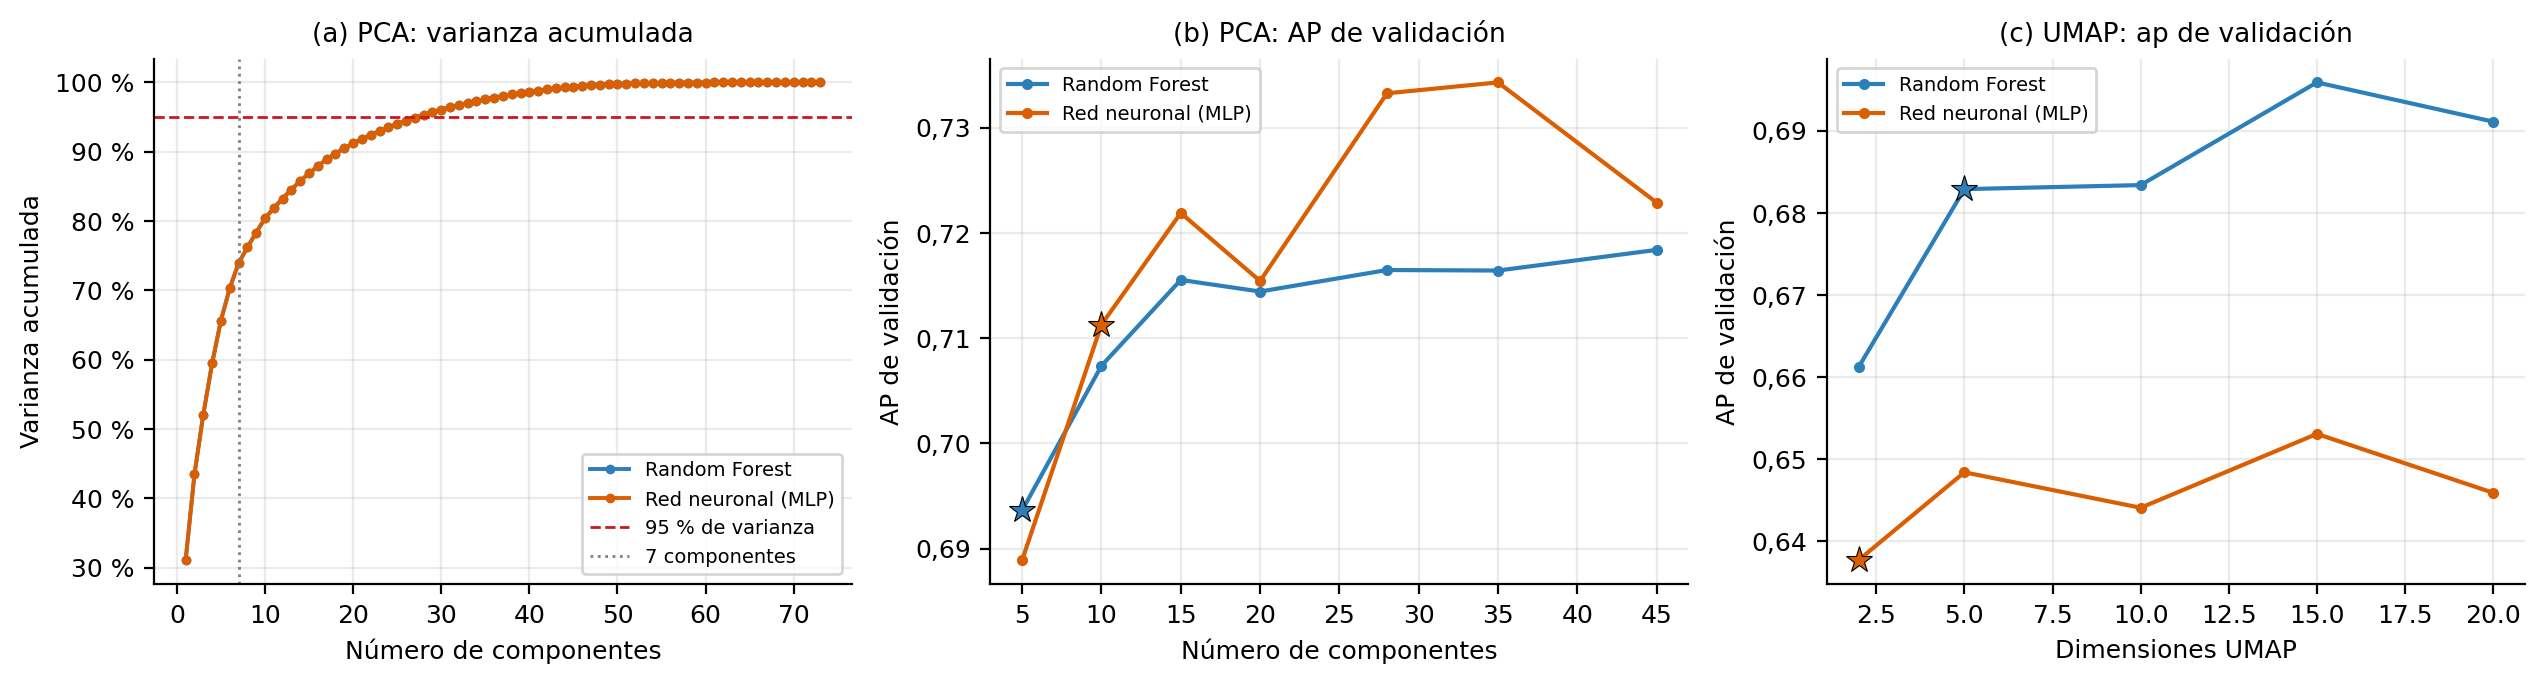

[Abrir figura: fig05_reduccion.png](../informe_entregable_II_latex/figuras/fig05_reduccion.png)

**Figura 6: proyeccion UMAP 2D en prueba** (`informe_entregable_II_latex/figuras/fig06_umap_2d.png`)

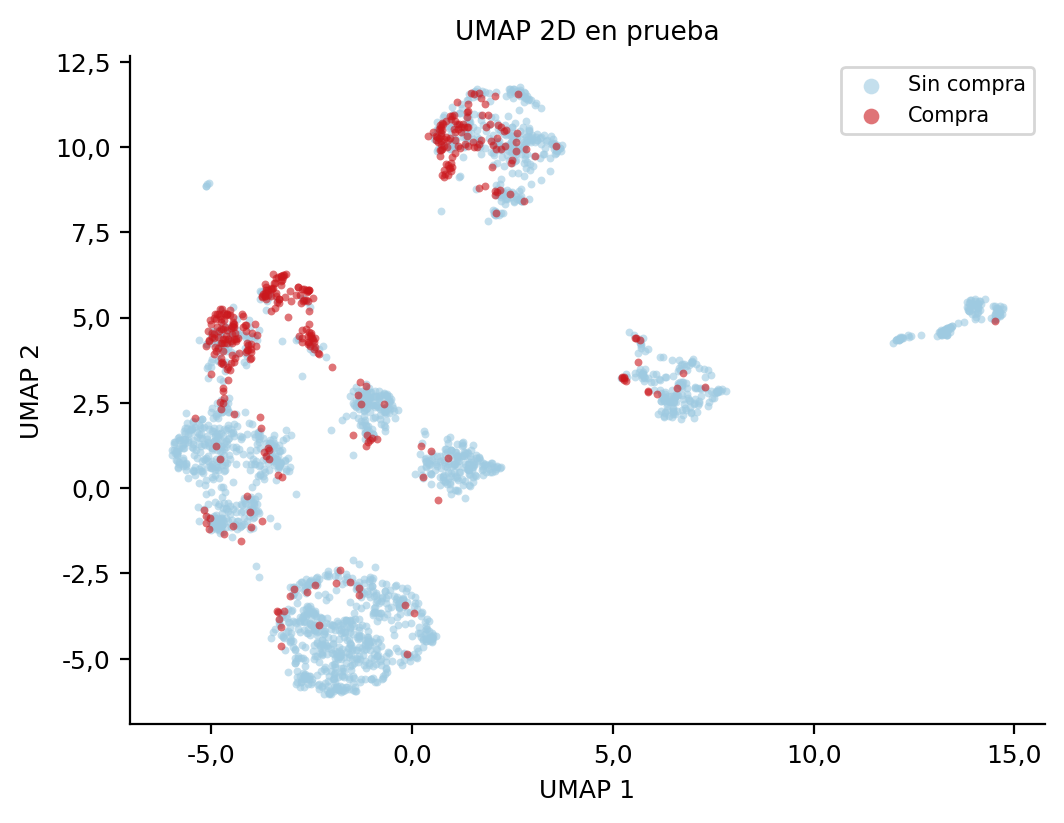

[Abrir figura: fig06_umap_2d.png](../informe_entregable_II_latex/figuras/fig06_umap_2d.png)

**AP en entrenamiento y validación** (`resultados/figuras/fig04_train_vs_validacion.png`)

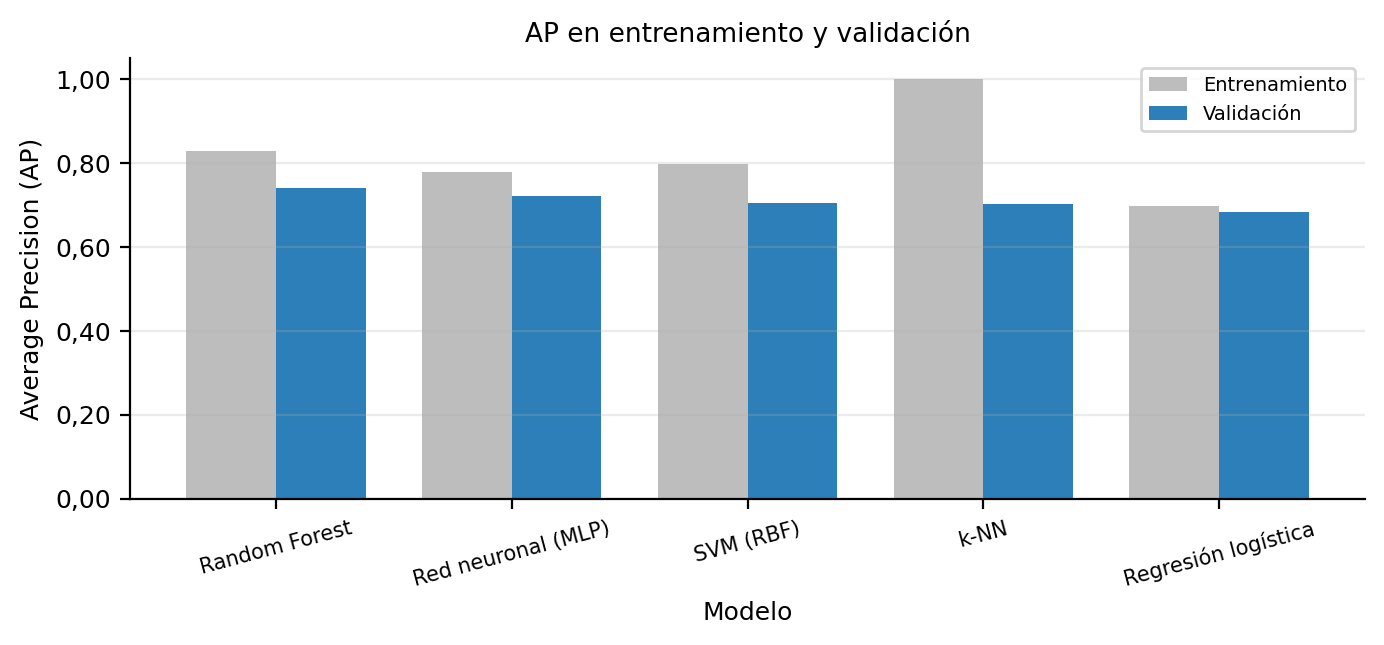

[Abrir figura: fig04_train_vs_validacion.png](../resultados/figuras/fig04_train_vs_validacion.png)

**Matrices de confusión en prueba** (`resultados/figuras/fig07_matrices_confusion_test.png`)

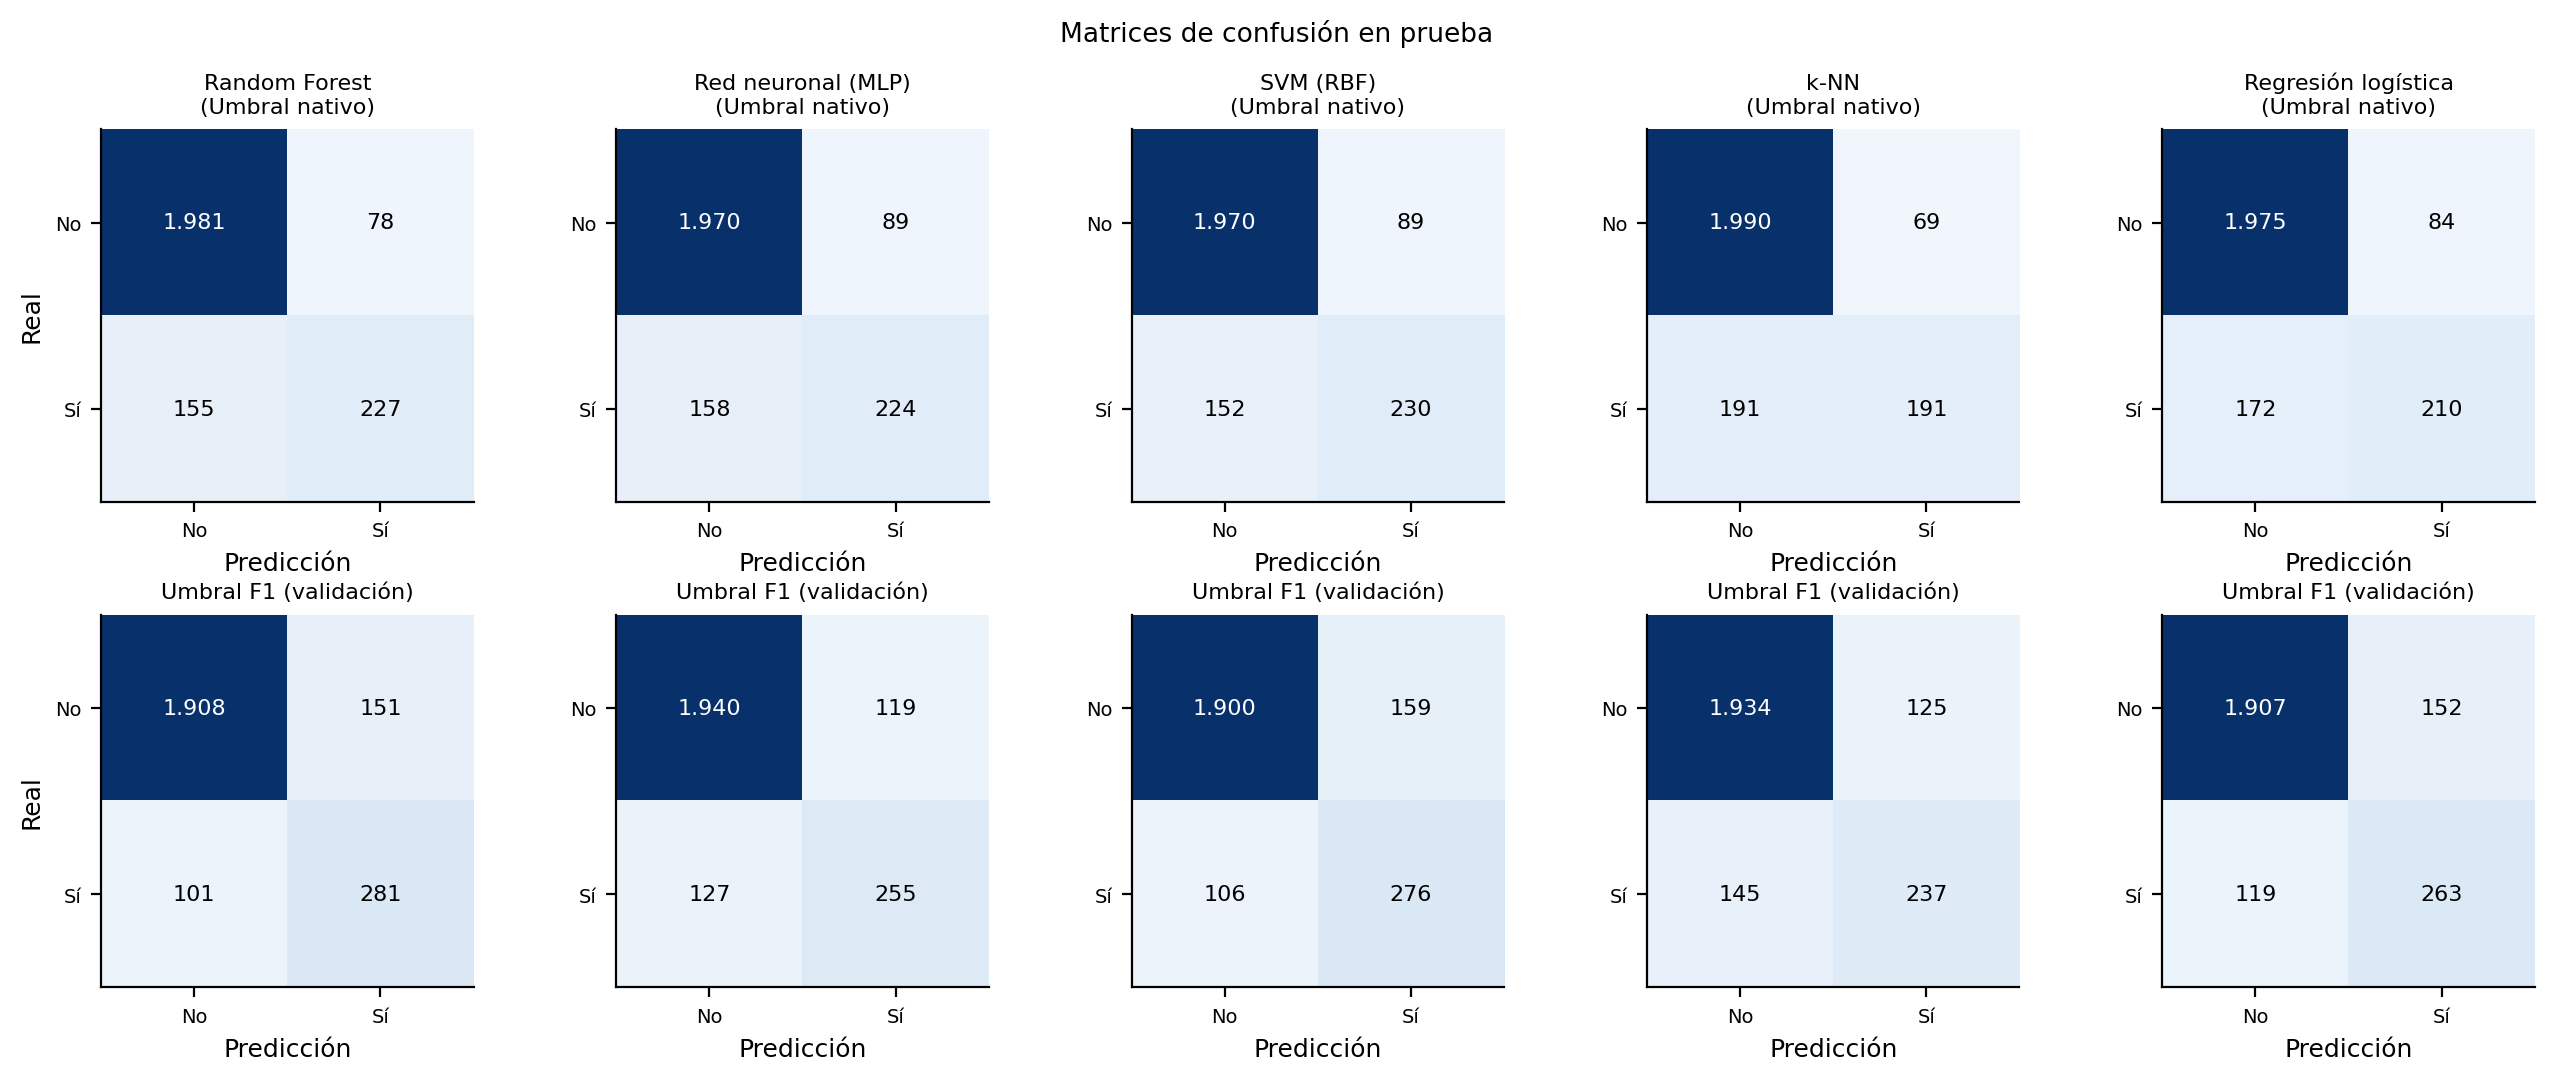

[Abrir figura: fig07_matrices_confusion_test.png](../resultados/figuras/fig07_matrices_confusion_test.png)

**AP con intervalos bootstrap** (`resultados/figuras/fig08_ap_intervalos.png`)

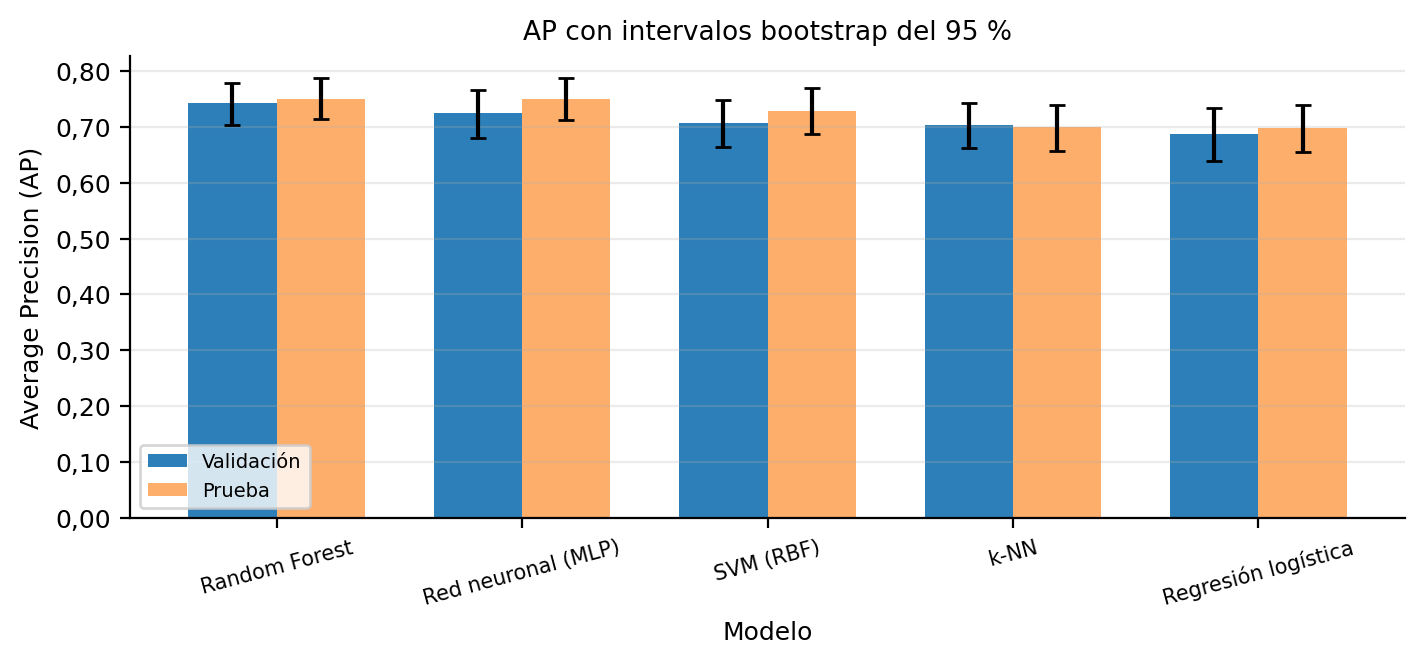

[Abrir figura: fig08_ap_intervalos.png](../resultados/figuras/fig08_ap_intervalos.png)

**Sensibilidad a PageValues** (`resultados/figuras/fig09_sensibilidad_pagevalues.png`)

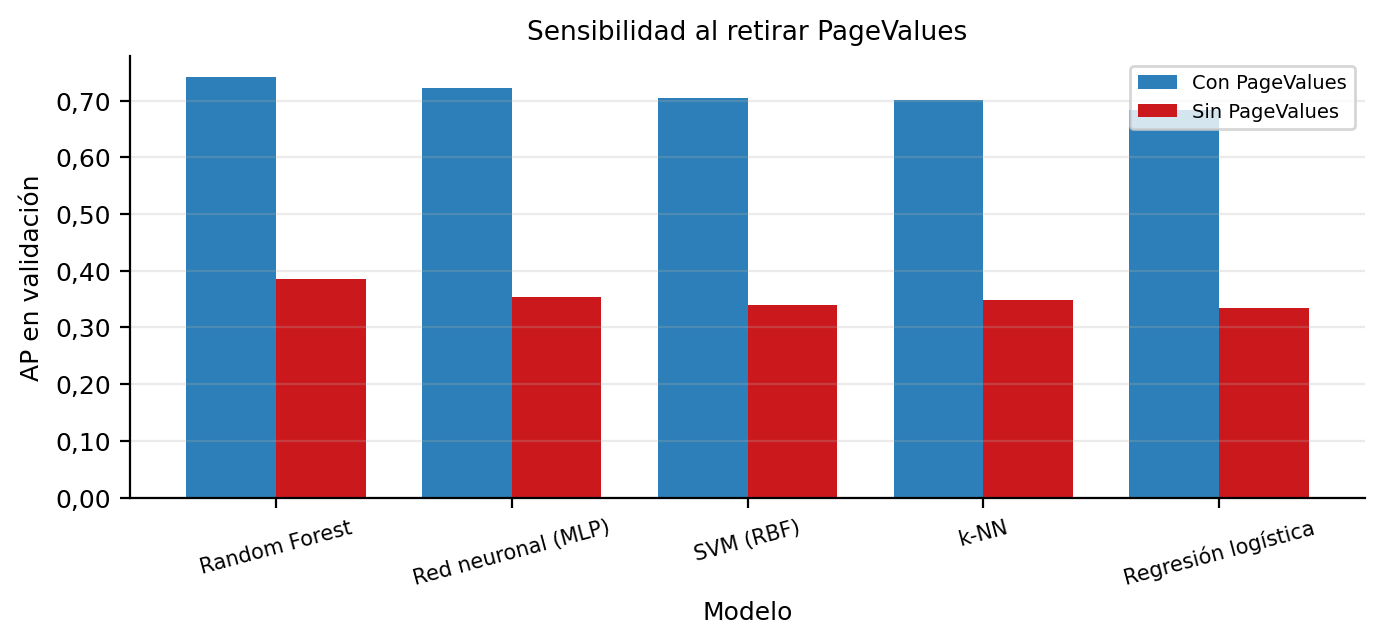

[Abrir figura: fig09_sensibilidad_pagevalues.png](../resultados/figuras/fig09_sensibilidad_pagevalues.png)

**Ablación de SpecialDay** (`resultados/figuras/fig10_ablacion_specialday.png`)

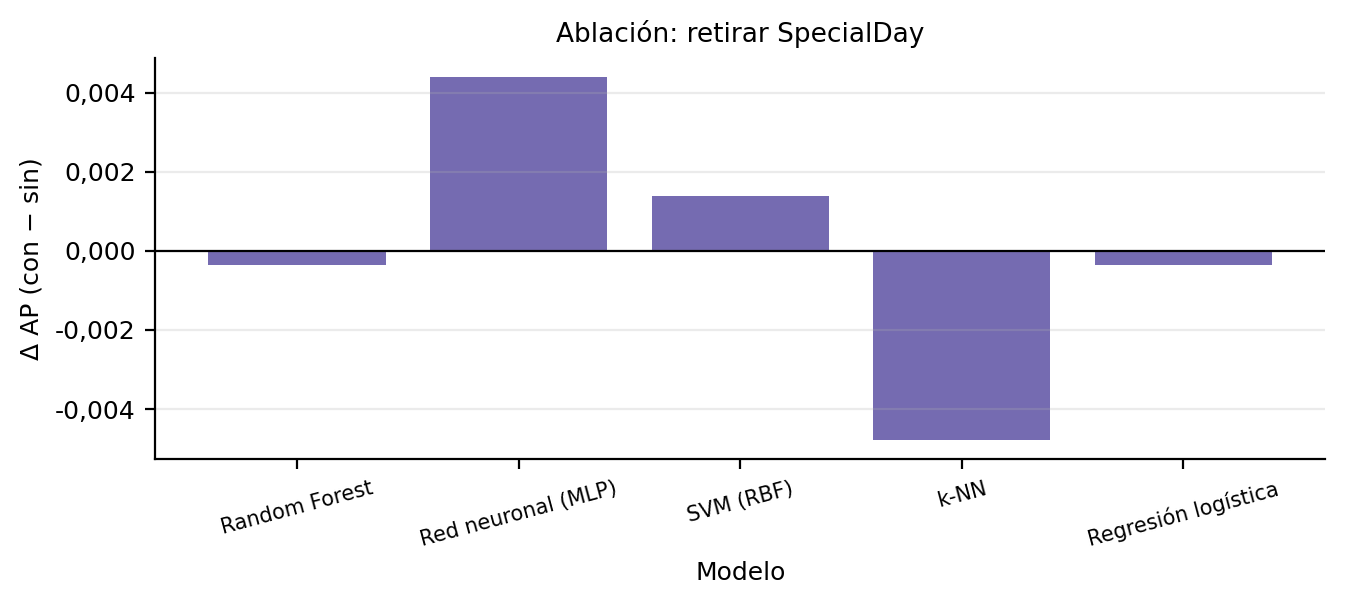

[Abrir figura: fig10_ablacion_specialday.png](../resultados/figuras/fig10_ablacion_specialday.png)

**Comparación de reducción** (`resultados/figuras/fig13_comparacion_reduccion.png`)

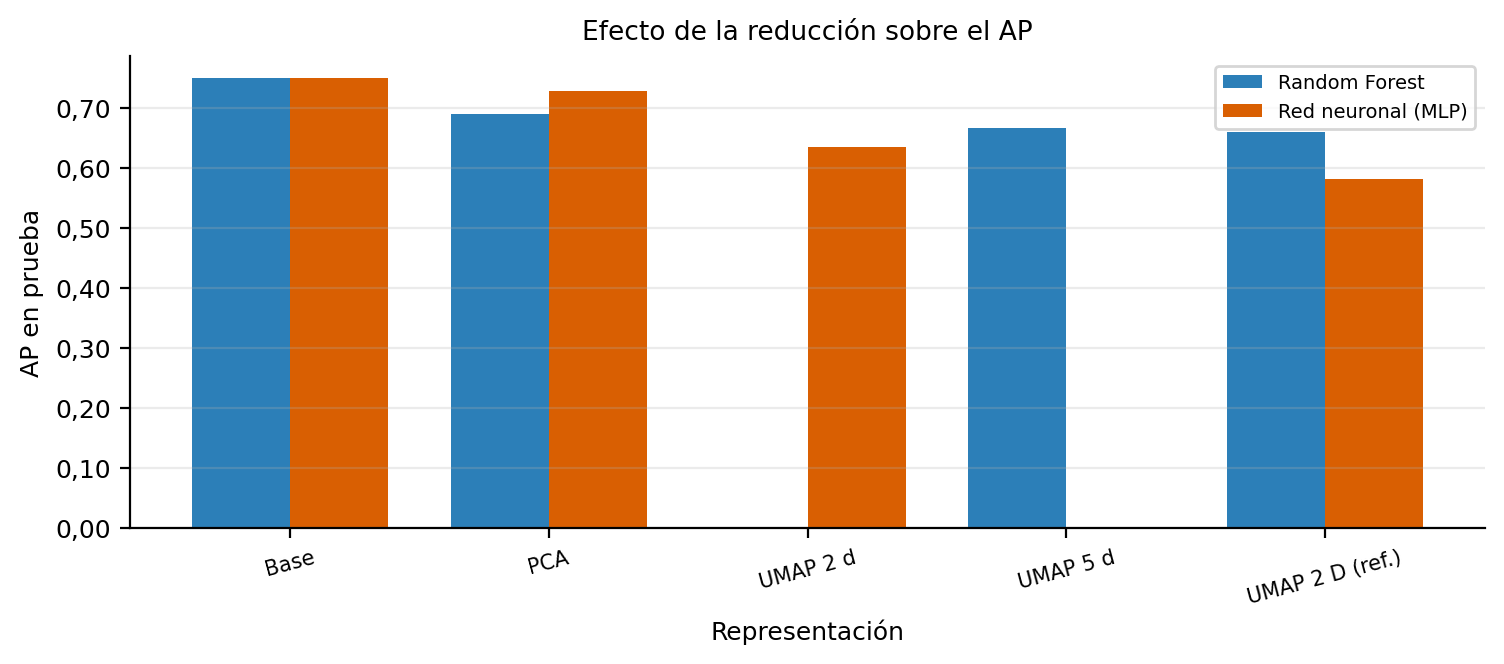

[Abrir figura: fig13_comparacion_reduccion.png](../resultados/figuras/fig13_comparacion_reduccion.png)

Figuras mostradas: 12.


In [14]:
figuras_informe = [
    ("fig01_clases_cobertura.png", "Figura 1: clases y cobertura mensual"),
    ("fig02_hiperparametros.png", "Figura 2: efecto de los hiperparametros"),
    ("fig03_pr_roc_validacion.png", "Figura 3: curvas precision-recall y ROC en validacion"),
    ("fig04_variables_auc.png", "Figura 4: variables con mayor AUC univariado"),
    ("fig05_reduccion.png", "Figura 5: PCA, UMAP y comparacion con la base"),
    ("fig06_umap_2d.png", "Figura 6: proyeccion UMAP 2D en prueba"),
]
vistas = set()
for nombre, titulo in figuras_informe:
    if mostrar_figura(nombre, titulo, carpetas=(FIG_INFORME, FIG_NOTEBOOK, RES / "figuras_informe")):
        vistas.add(nombre)

# Figuras del notebook: las seis que escribe src/figuras.py en resultados/figuras,
# las fig_nb_*.png si el generador cambia de nomenclatura y, como ultimo recurso,
# cualquier PNG del flujo, para no ocultar figuras reales.
figuras_notebook = [
    ("fig04_train_vs_validacion.png", "AP en entrenamiento y validación"),
    ("fig07_matrices_confusion_test.png", "Matrices de confusión en prueba"),
    ("fig08_ap_intervalos.png", "AP con intervalos bootstrap"),
    ("fig09_sensibilidad_pagevalues.png", "Sensibilidad a PageValues"),
    ("fig10_ablacion_specialday.png", "Ablación de SpecialDay"),
    ("fig13_comparacion_reduccion.png", "Comparación de reducción"),
]
for nombre, titulo in figuras_notebook:
    if mostrar_figura(nombre, titulo, carpetas=(FIG_NOTEBOOK, RES / "figuras_informe")):
        vistas.add(nombre)

candidatas_nb = []
for carpeta in (FIG_NOTEBOOK, FIG_INFORME, RES / "figuras_informe"):
    if carpeta.is_dir():
        candidatas_nb.extend(sorted(carpeta.glob("fig_nb_*.png")))
for ruta in candidatas_nb:
    if ruta.name in vistas:
        continue
    mostrar_figura(
        ruta.name,
        ruta.stem.replace("_", " "),
        carpetas=(FIG_NOTEBOOK, RES / "figuras_informe", FIG_INFORME),
    )
    vistas.add(ruta.name)

for carpeta in (FIG_NOTEBOOK, RES / "figuras_informe"):
    if not carpeta.is_dir():
        continue
    for ruta in sorted(carpeta.glob("*.png")):
        if ruta.name in vistas:
            continue
        mostrar_figura(
            ruta.name,
            ruta.stem.replace("_", " "),
            carpetas=(FIG_NOTEBOOK, RES / "figuras_informe"),
        )
        vistas.add(ruta.name)

if not vistas:
    print("AVISO: no hay figuras generadas; ejecute la etapa de figuras o active RECALCULAR.")
else:
    print(f"Figuras mostradas: {len(vistas)}.")

## 12. Lectura, limitaciones y archivos leidos

Las tablas de este notebook no sustituyen al informe: son una lectura directa de los artefactos
de la ejecución. Cualquier conclusion sobre el mejor modelo, la utilidad de una variable o el
efecto de una transformación debe contrastarse con la tabla y el intervalo correspondientes.

Limitaciones que deben acompanar la lectura:

- La partición de prueba fue consultada en el análisis histórico; los intervalos bootstrap son
  condicionales a los modelos y a la partición fijados, no una validación independiente.
- Las cifras de Lin y Sakar et al. provienen de protocolos distintos y no se reproducen aquí.
- El modo `RECALCULAR = True` reentrena y puede sobrescribir resultados y figuras; no se ejecuto
  durante la creacion de este notebook.
- Si falta un archivo, la seccion lo advierte y el resto del notebook continua.

La tabla final registra los archivos efectivamente leidos en esta ejecución, sin rutas absolutas.

In [15]:
if REGISTRO:
    trazabilidad = pd.DataFrame(REGISTRO).drop_duplicates(subset=["archivo"])
    display(Markdown(f"**Archivos leidos en esta ejecucion ({len(trazabilidad)})**"))
    display(trazabilidad)
else:
    print("No se leyo ningun archivo de resultados.")

**Archivos leidos en esta ejecucion (35)**

,archivo,filas,columnas
0,resultados/manifiesto.json,NaN,NaN
1,resultados/auditoria.json,NaN,NaN
2,resultados/tabla_variables.csv,18.0,9.0
3,resultados/resumen_particiones.csv,3.0,5.0
4,resultados/cobertura_mensual_train.csv,10.0,3.0
5,resultados/mejores_configuraciones.csv,5.0,12.0
6,resultados/ganador.json,NaN,NaN
7,resultados/validacion_top3.csv,15.0,12.0
8,resultados/cv_todos_los_candidatos.csv,730.0,36.0
9,resultados/evaluacion_familias/cv_intervalos.csv,15.0,8.0
